<center><h1>Magdum_Seona_HW4</h1></center>
<br>
<br>

Name: Seona Magdum
<br>
Github Username: seo2003
<br>
USC ID: 6077378254

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

In [59]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_score
)
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve,
    roc_auc_score,
    auc
)

In [60]:
print(os.listdir("../data"))

['.DS_Store', 'bending1', 'walking', 'bending2', 'standing', 'sitting', 'lying', 'cycling']


Get the AReM Data Set

In [61]:
for folder in os.listdir("../data"):
    if folder != ".DS_Store":
        print(folder, os.listdir("../data/" + folder)[:5])

bending1 ['dataset7.csv', 'dataset6.csv', 'dataset4.csv', 'dataset5.csv', 'dataset1.csv']
walking ['dataset7.csv', 'dataset6.csv', 'dataset4.csv', 'dataset5.csv', 'dataset1.csv']
bending2 ['dataset6.csv', 'dataset4.csv', 'dataset5.csv', 'dataset1.csv', 'dataset2.csv']
standing ['dataset7.csv', 'dataset6.csv', 'dataset4.csv', 'dataset5.csv', 'dataset1.csv']
sitting ['dataset7.csv', 'dataset6.csv', 'dataset4.csv', 'dataset5.csv', 'dataset1.csv']
lying ['dataset7.csv', 'dataset6.csv', 'dataset4.csv', 'dataset5.csv', 'dataset1.csv']
cycling ['dataset7.csv', 'dataset6.csv', 'dataset4.csv', 'dataset5.csv', 'dataset1.csv']


### (b) Splitting Data

In [62]:
#set relative path
data_path = "../data"

#training and testing file paths
train_files = []
test_files = []

#loop through each folder
for activity in sorted(os.listdir(data_path)):
    activity_path = os.path.join(data_path, activity)

    #skip if not folder
    if not os.path.isdir(activity_path):
        continue

    #loop through each file in folder
    for filename in sorted(os.listdir(activity_path)):

        #CSV files
        if not filename.endswith(".csv"):
            continue

        #relative path to current CSV file
        file_path = os.path.join(activity_path, filename)

        dataset_number = int(filename.replace("dataset", "").replace(".csv", ""))

        # For bending activities, use datasets 1 and 2 for testing
        if activity in ["bending1", "bending2"]:
            if dataset_number in [1, 2]:
                test_files.append(file_path)
            else:
                train_files.append(file_path)

        #use datasets 1, 2, and 3 for testing
        else:
            if dataset_number in [1, 2, 3]:
                test_files.append(file_path)
            else:
                train_files.append(file_path)

print("Training files:", len(train_files))
print("Testing files:", len(test_files))

Training files: 69
Testing files: 19


### (c) Feature Extraction

In [63]:

file_path = "../data/bending1/dataset1.csv"

df = pd.read_csv(file_path, skiprows=4)

print(df.head())
print(df.columns)
print(df.shape)

import os
import pandas as pd

data_path = "../data"

#six sensor measurements
sensor_columns = [
    "avg_rss12", "var_rss12",
    "avg_rss13", "var_rss13",
    "avg_rss23", "var_rss23"
]

#empty list to store the features for each instance
all_features = []

for activity in sorted(os.listdir(data_path)):
    activity_path = os.path.join(data_path, activity)

    if not os.path.isdir(activity_path):
        continue

    for filename in sorted(os.listdir(activity_path)):

        #only CSV files
        if not filename.endswith(".csv"):
            continue

        #create the relative path to the current CSV file
        file_path = os.path.join(activity_path, filename)

        #bending2 dataset4 file, which used spaces instead of commas
        if activity == "bending2" and filename == "dataset4.csv":
            df = pd.read_csv(file_path, skiprows=5, sep=r"\s+", header=None)

            # Assign column names
            df.columns = [
                "time", "avg_rss12", "var_rss12",
                "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"
            ]

        else:
            #load the CSV file and skip the four metadata rows and use only the first seven columns
            df = pd.read_csv(file_path, skiprows=4, usecols=range(7))

        #store the instance name and its corresponding activity label
        row = {
            "instance": activity + "_" + filename.replace(".csv", ""),
            "activity": activity
        }

        #calculate statistical features
        for i, column in enumerate(sensor_columns, start=1):
            values = df[column]
            row[f"min_{i}"] = values.min()
            row[f"max_{i}"] = values.max()
            row[f"mean_{i}"] = values.mean()
            row[f"median_{i}"] = values.median()
            row[f"std_{i}"] = values.std()
            row[f"q1_{i}"] = values.quantile(0.25)
            row[f"q3_{i}"] = values.quantile(0.75)
        all_features.append(row)

features_df = pd.DataFrame(all_features)

print("Dataset shape:", features_df.shape)
features_df.head()

features_df.to_csv("time_domain_features.csv", index=False)

import numpy as np
import pandas as pd

#select 42 feature columns
feature_columns = [
    col for col in features_df.columns
    if col not in ["instance", "activity"]
]

#sd of all 88 instances
standard_deviations = features_df[feature_columns].std()

#bootstrap 
n_bootstrap = 10000
np.random.seed(42)

bootstrap_results = []

for column in feature_columns:
    values = features_df[column].values
    n = len(values)

    bootstrap_stds = []

    for i in range(n_bootstrap):
        sample = np.random.choice(values, size=n, replace=True)

        #sd of bootstrap sample
        bootstrap_stds.append(np.std(sample, ddof=1))

    #90% CI
    lower = np.percentile(bootstrap_stds, 5)
    upper = np.percentile(bootstrap_stds, 95)

    bootstrap_results.append({
        "Feature": column,
        "Standard Deviation": standard_deviations[column],
        "90% CI Lower": lower,
        "90% CI Upper": upper
    })

results_df = pd.DataFrame(bootstrap_results)

print(results_df.round(4).to_string(index=False))

   # Columns: time  avg_rss12  var_rss12  avg_rss13  var_rss13  avg_rss23  \
0                0      39.25       0.43      22.75       0.43      33.75   
1              250      39.25       0.43      23.00       0.00      33.00   
2              500      39.25       0.43      23.25       0.43      33.00   
3              750      39.50       0.50      23.00       0.71      33.00   
4             1000      39.50       0.50      24.00       0.00      33.00   

   var_rss23  
0        1.3  
1        0.0  
2        0.0  
3        0.0  
4        0.0  
Index(['# Columns: time', 'avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13',
       'avg_rss23', 'var_rss23'],
      dtype='object')
(480, 7)
Dataset shape: (88, 44)
 Feature  Standard Deviation  90% CI Lower  90% CI Upper
   min_1              9.5700        8.2646       10.7562
   max_1              4.3944        3.3215        5.2776
  mean_1              5.3357        4.7094        5.8841
median_1              5.4401        4.7815        5.

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

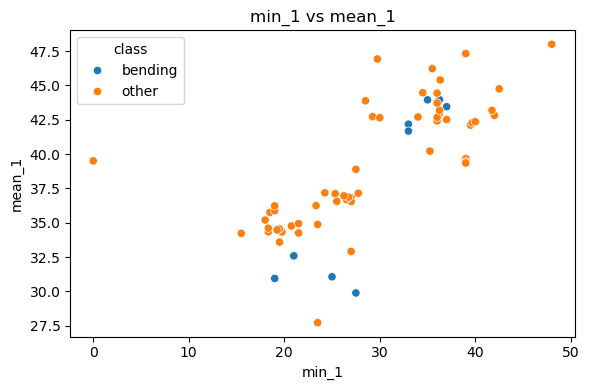

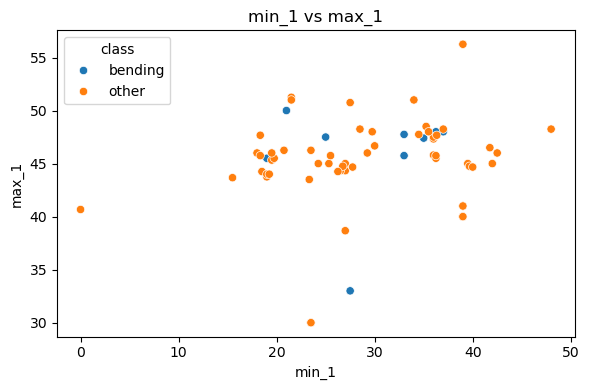

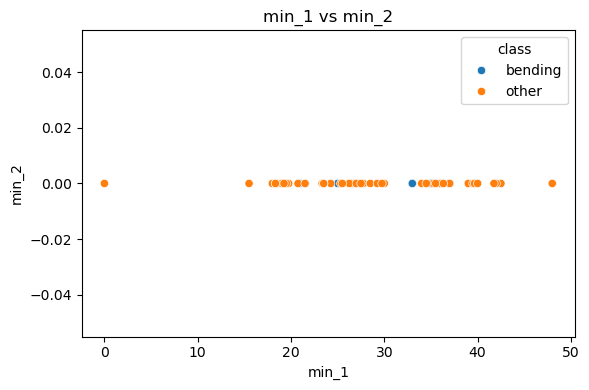

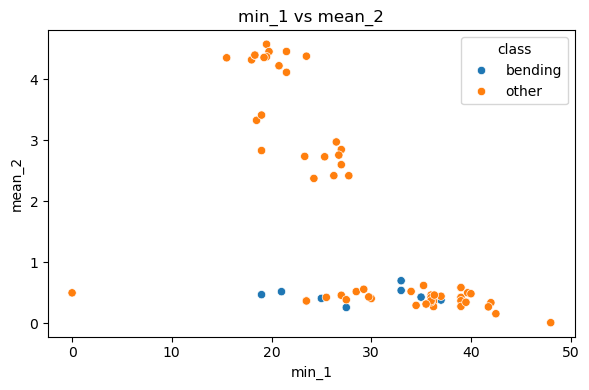

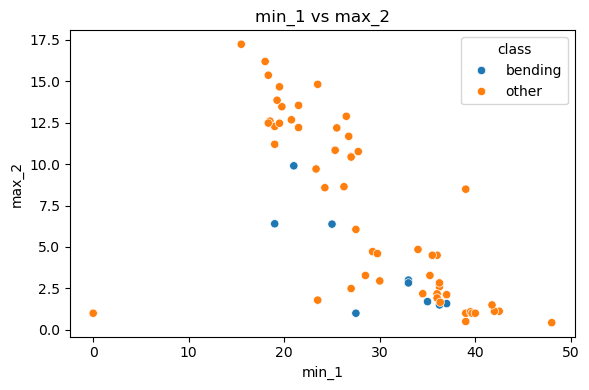

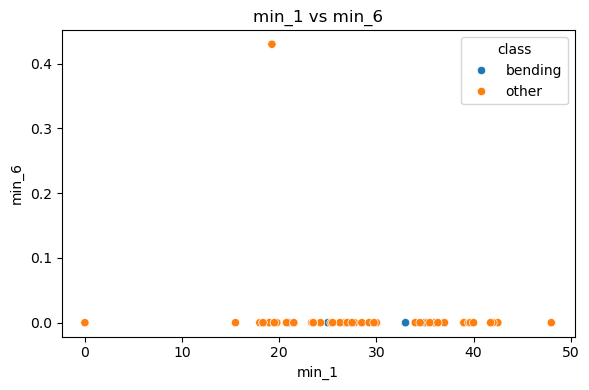

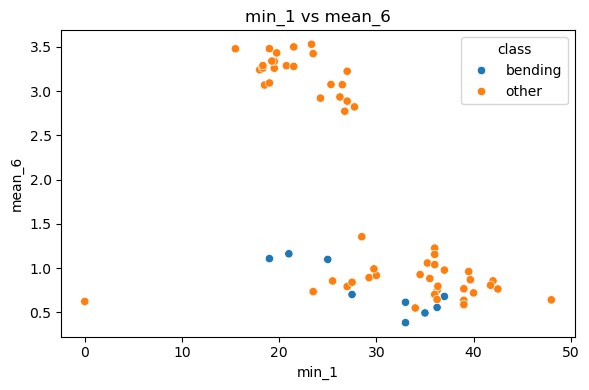

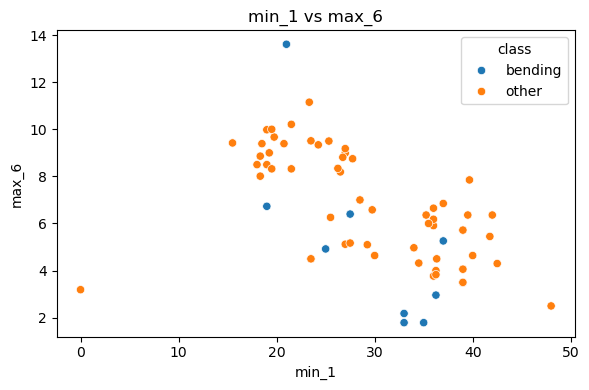

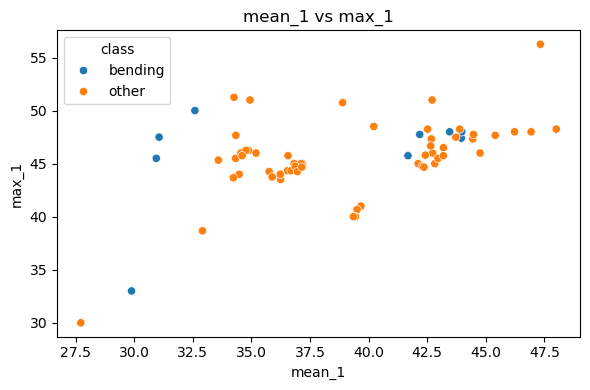

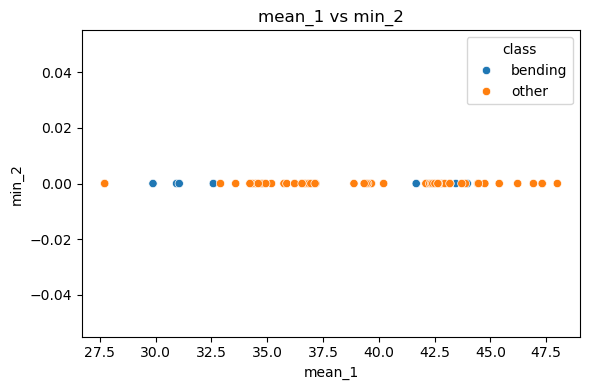

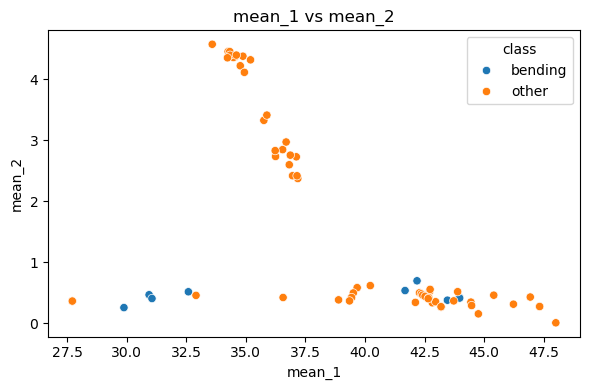

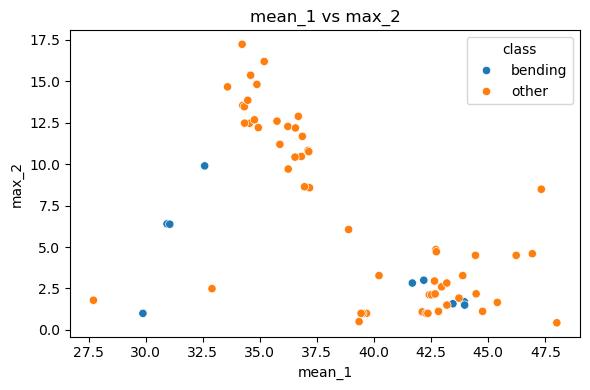

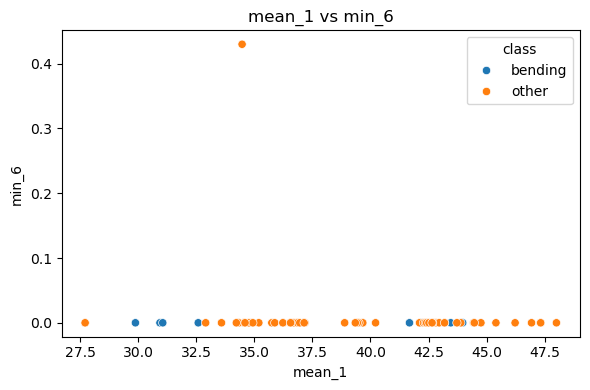

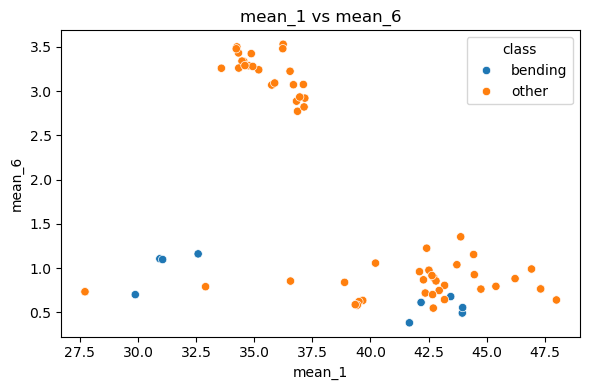

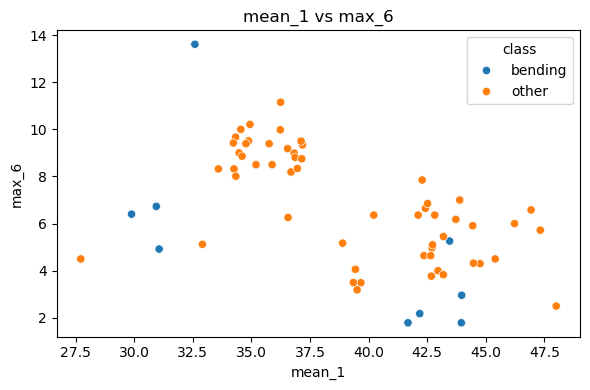

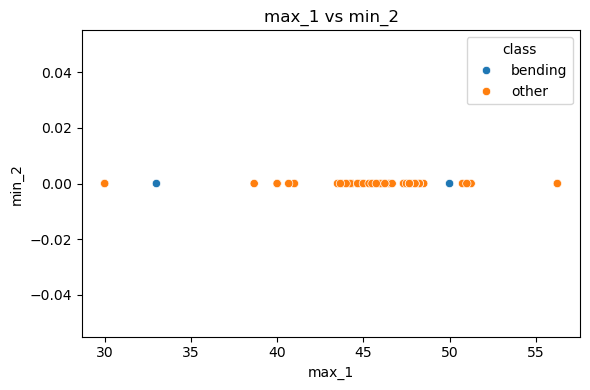

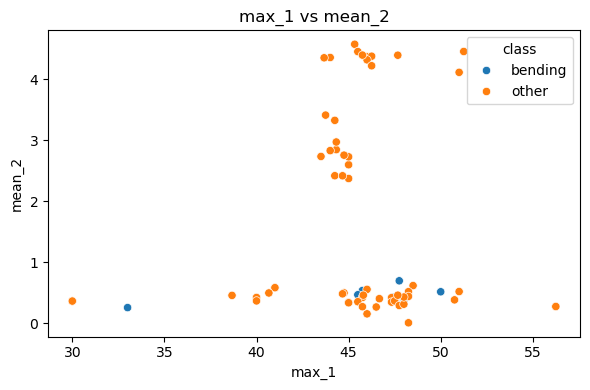

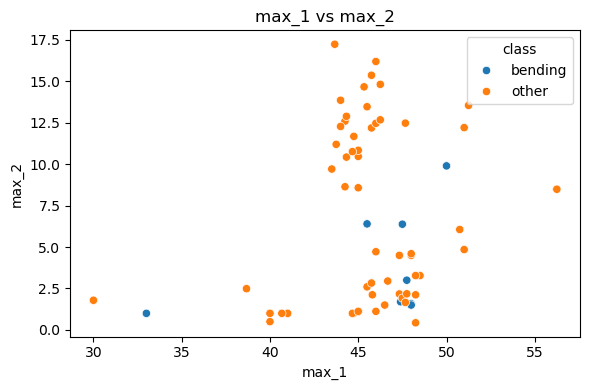

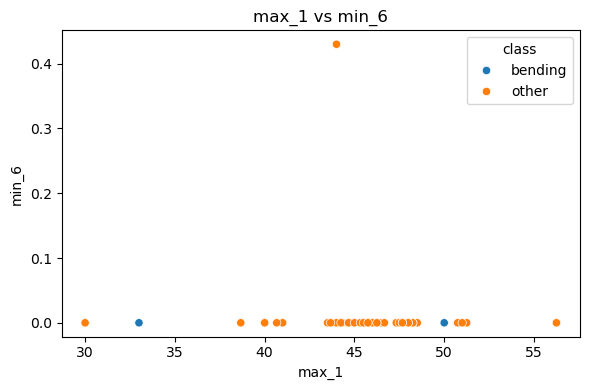

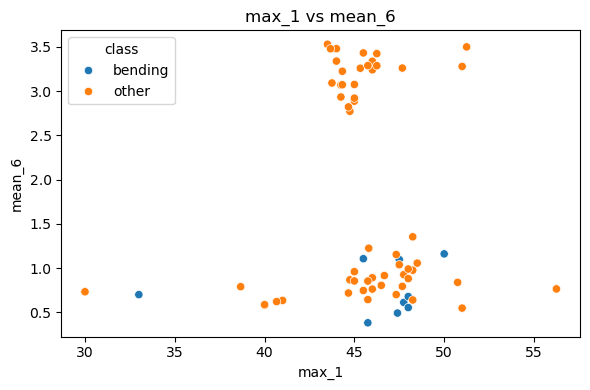

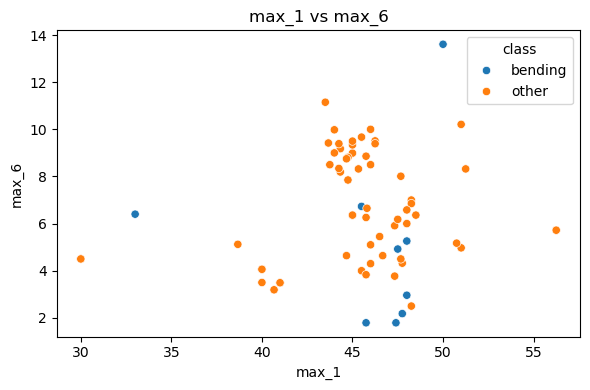

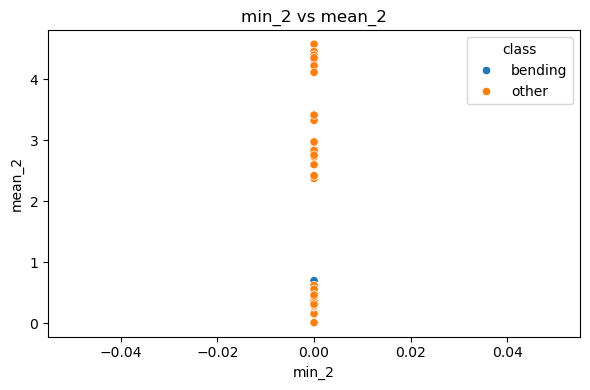

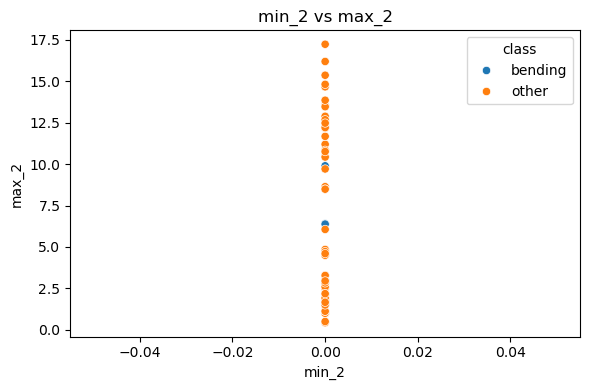

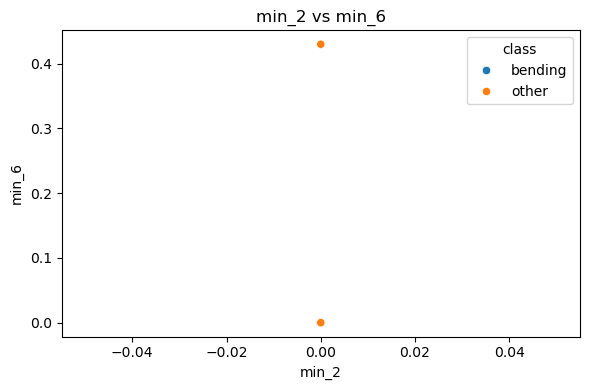

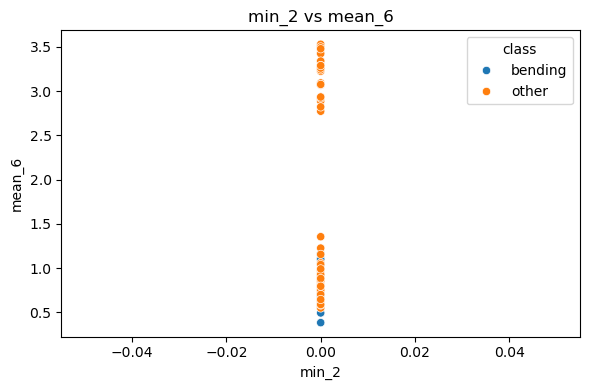

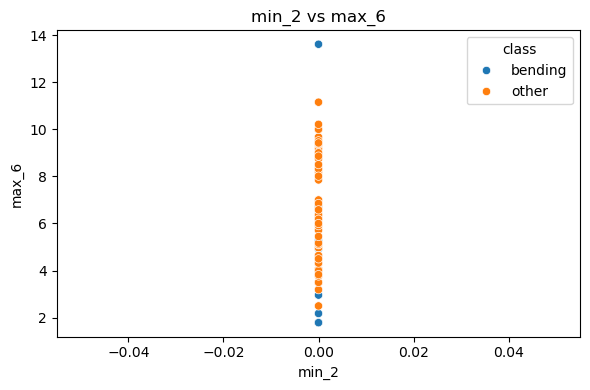

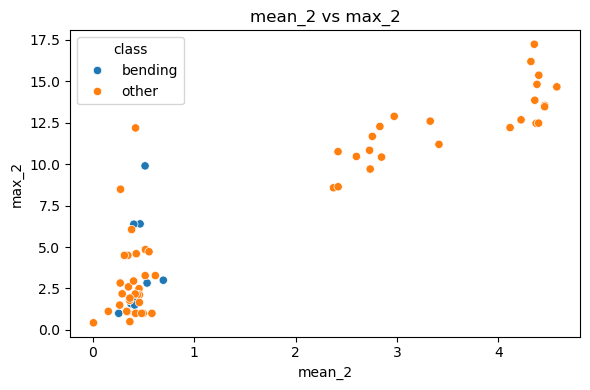

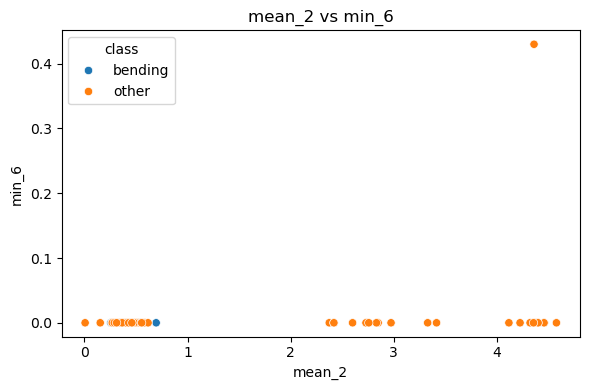

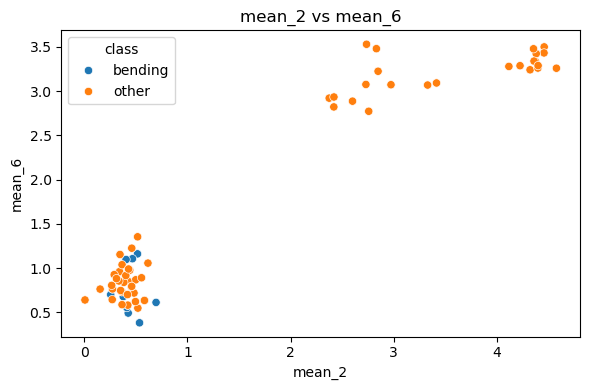

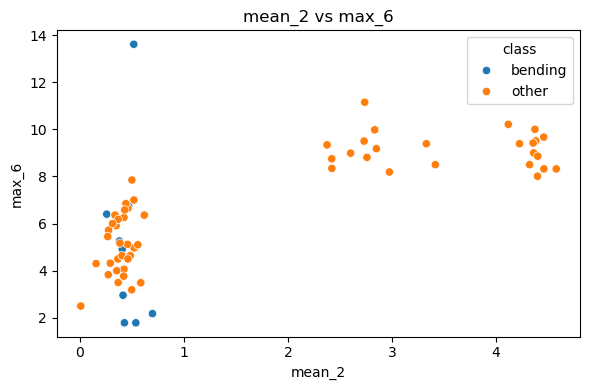

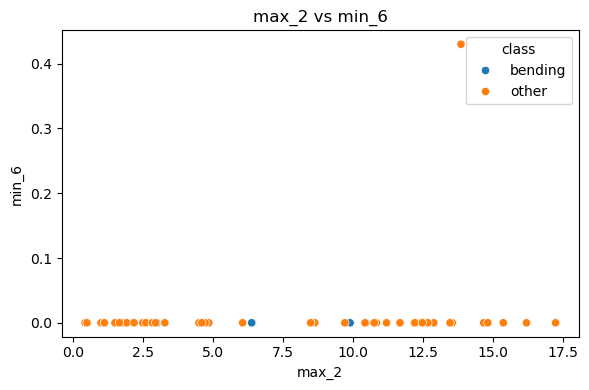

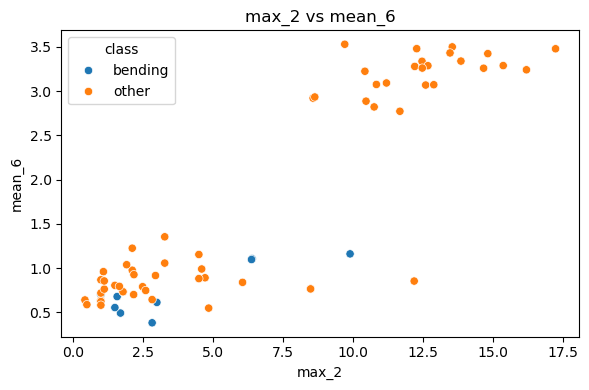

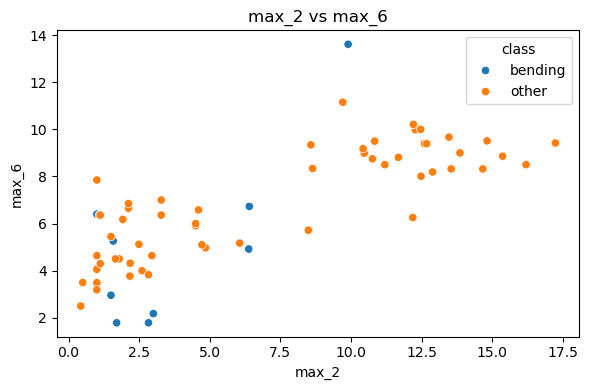

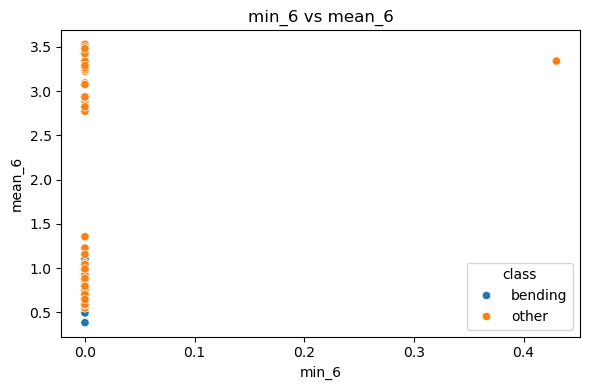

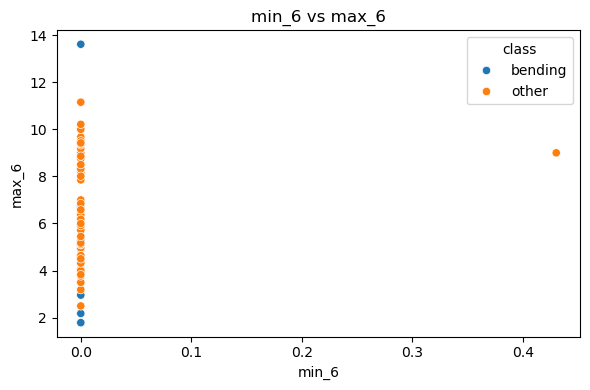

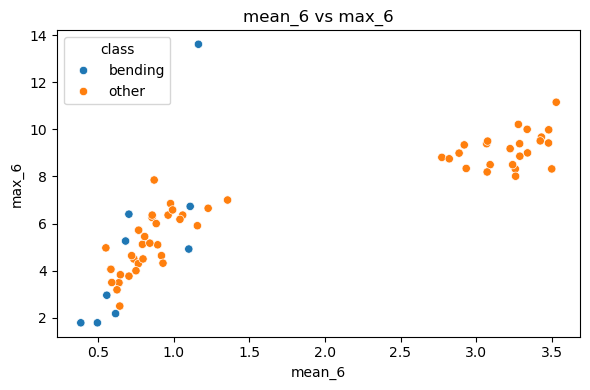

In [64]:
# get instance names
instances = []

for file_path in train_files:
    activity = os.path.basename(os.path.dirname(file_path))
    filename = os.path.basename(file_path).replace(".csv", "")
    instances.append(activity + "_" + filename)

# Keep only the training instances
train_df = features_df[features_df["instance"].isin(instances)].copy()

# Label bending vs. other activities
train_df["class"] = train_df["activity"].apply(
    lambda x: "bending" if x in ["bending1", "bending2"] else "other"
)


#plot scatterplots 
#chose min mean max in part 1 c 
features = [
    "min_1", "mean_1", "max_1",
    "min_2", "mean_2", "max_2",
    "min_6", "mean_6", "max_6"
]

# Plot each unique pair of features
for i in range(len(features)):
    for j in range(i + 1, len(features)):
        plt.figure(figsize=(6, 4))

        sns.scatterplot(
            data=train_df,
            x=features[i],
            y=features[j],
            hue="class"
        )

        plt.title(features[i] + " vs " + features[j])
        plt.tight_layout()
        plt.show()



#### ii. Splitted Plots

Dataset shape: (138, 12)
            instance  part    class  min_1     mean_1  max_1  min_2    mean_2  \
0  bending1_dataset3     1  bending  36.50  44.057167  46.50    0.0  0.381042   
1  bending1_dataset3     2  bending  35.00  43.851833  47.40    0.0  0.471458   
2  bending1_dataset4     1  bending  33.75  43.278875  47.75    0.0  0.673292   
3  bending1_dataset4     2  bending  33.00  41.080750  46.00    0.0  0.718792   
4  bending1_dataset5     1  bending  33.00  41.621208  45.75    0.0  0.623083   

   max_2  min_6    mean_6  max_6  
0   1.50    0.0  0.598250   1.79  
1   1.70    0.0  0.388333   1.50  
2   3.00    0.0  0.640958   1.53  
3   2.86    0.0  0.586083   2.18  
4   2.83    0.0  0.419083   1.79  
Scatter plots for part 1


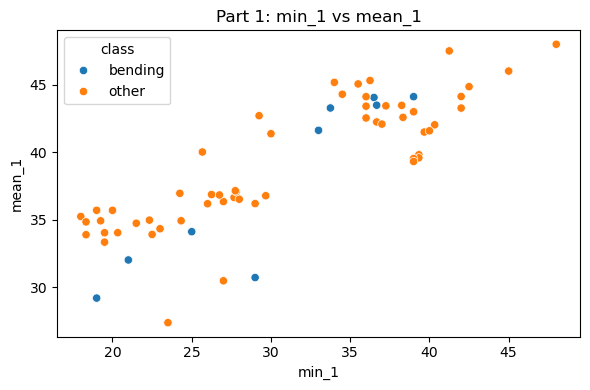

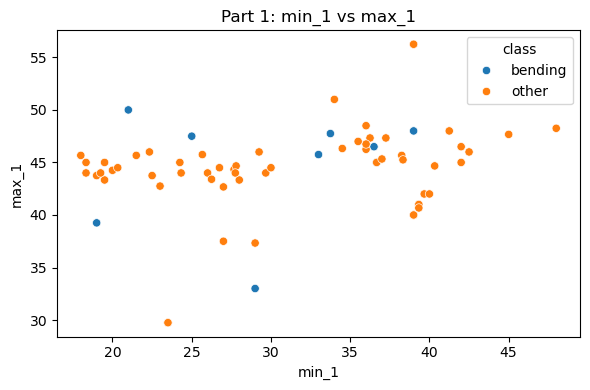

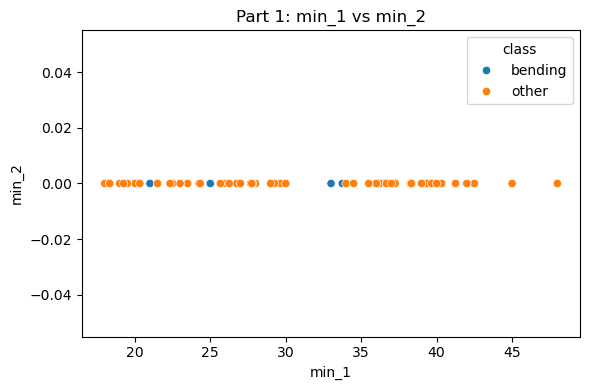

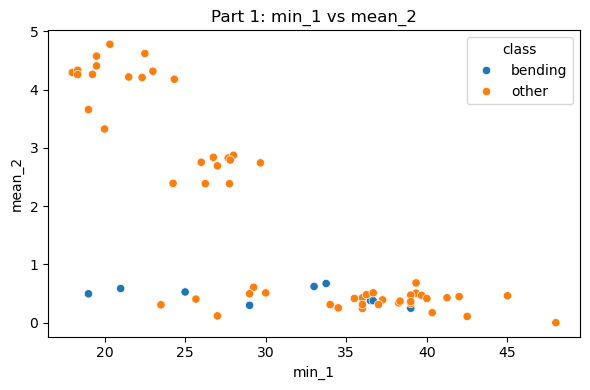

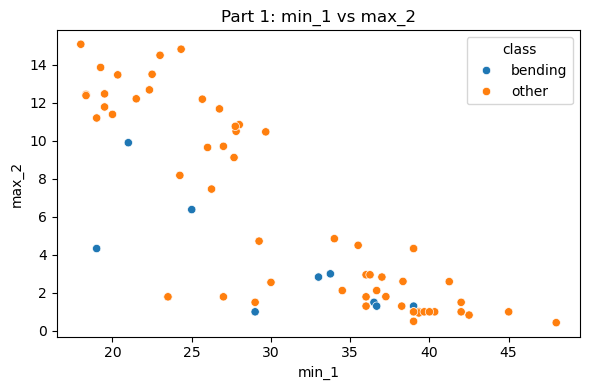

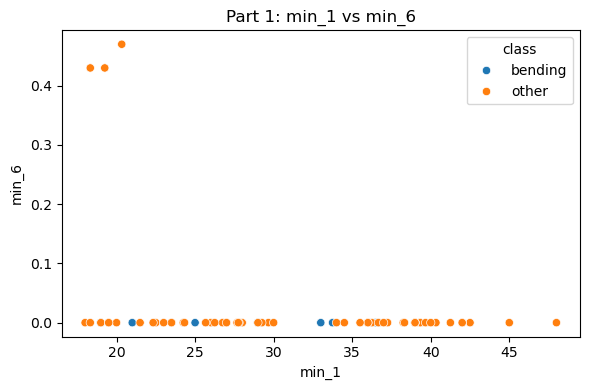

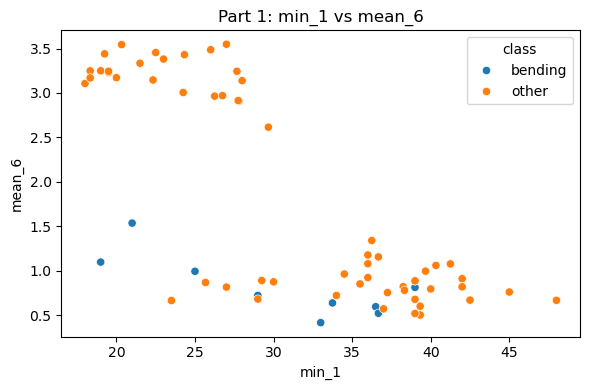

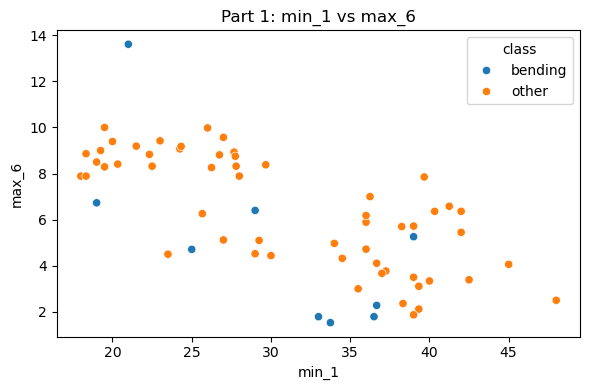

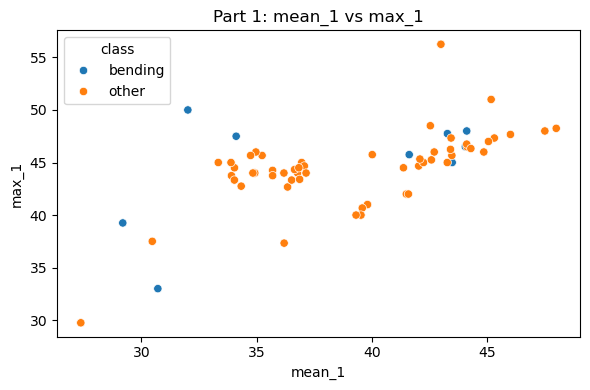

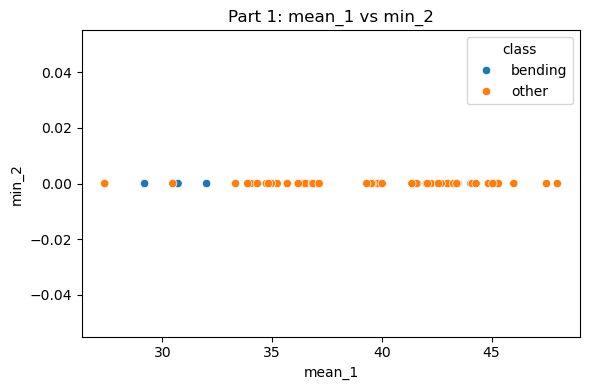

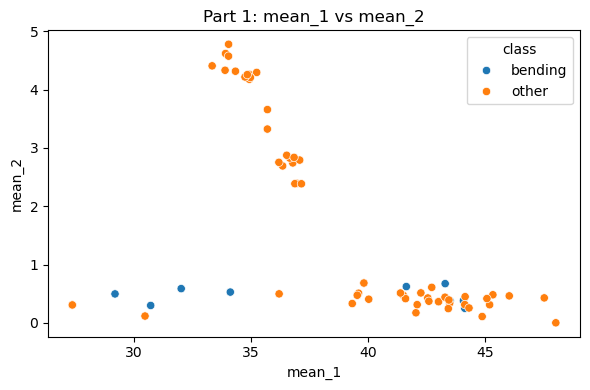

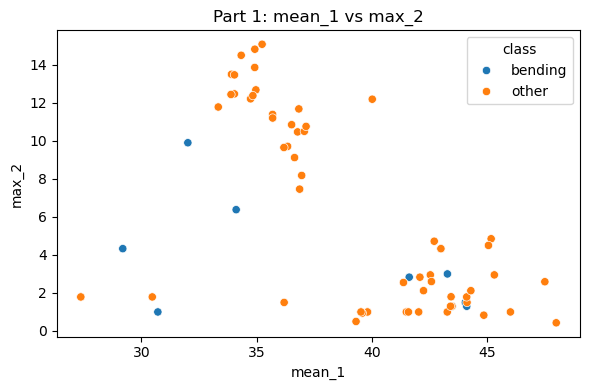

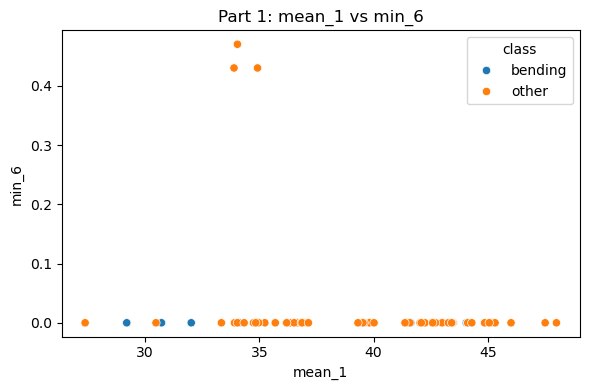

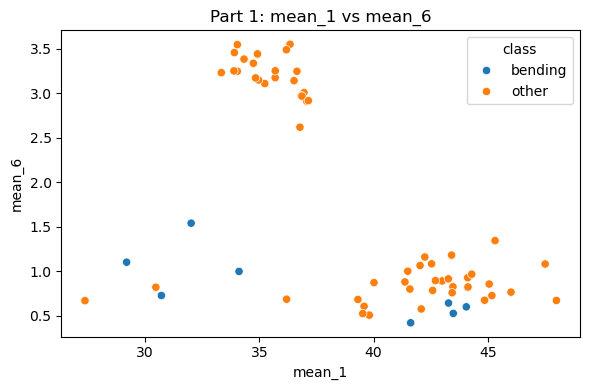

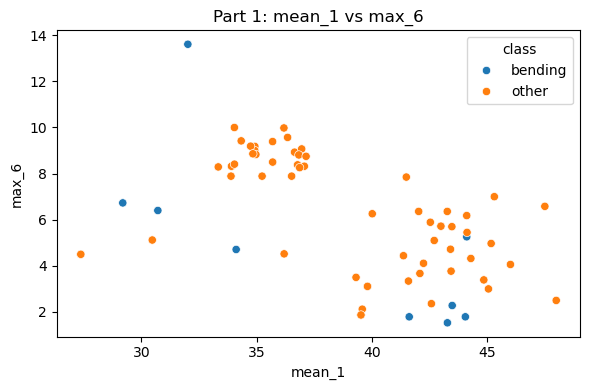

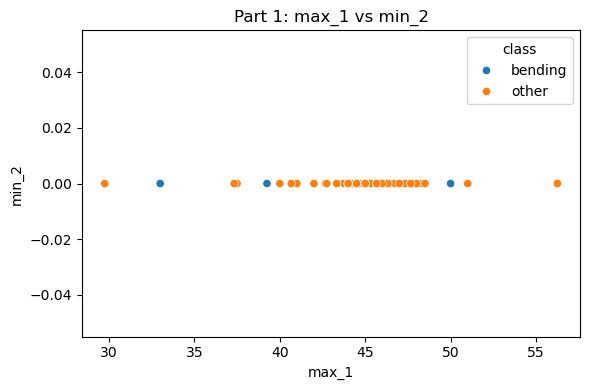

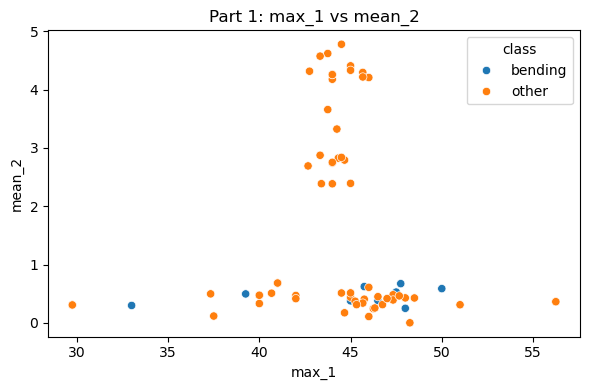

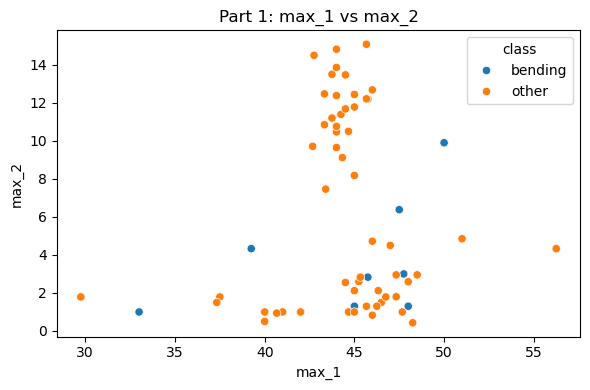

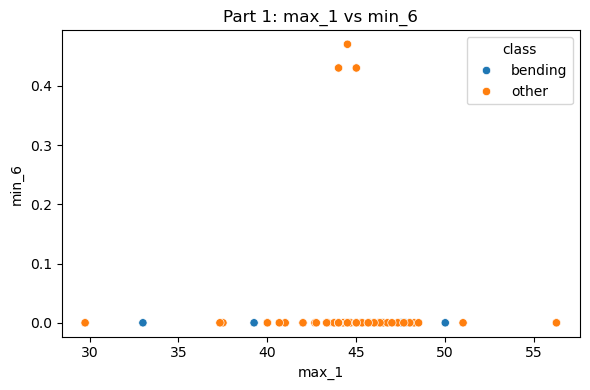

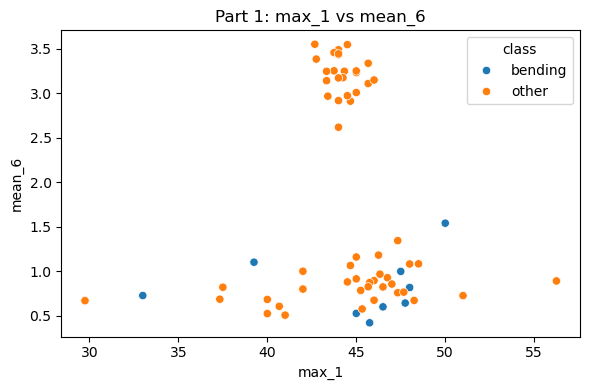

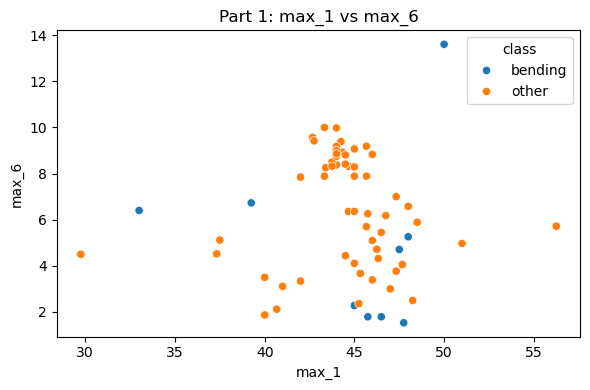

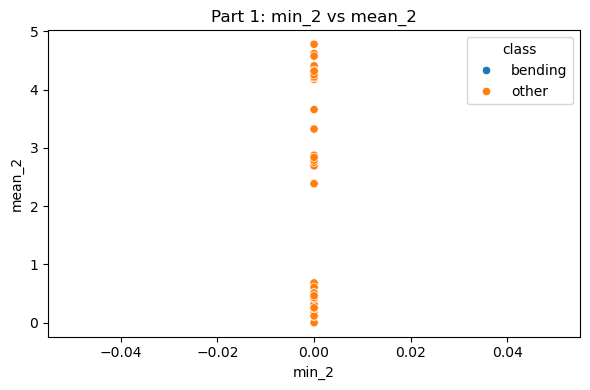

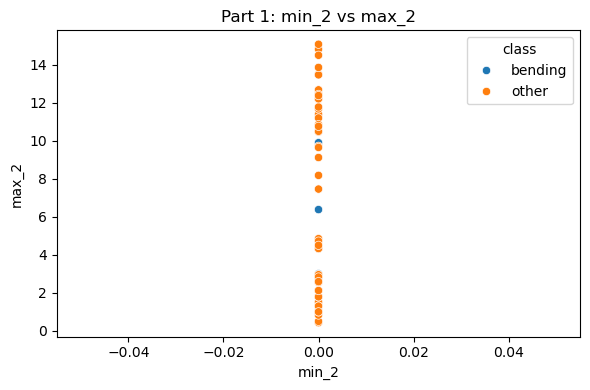

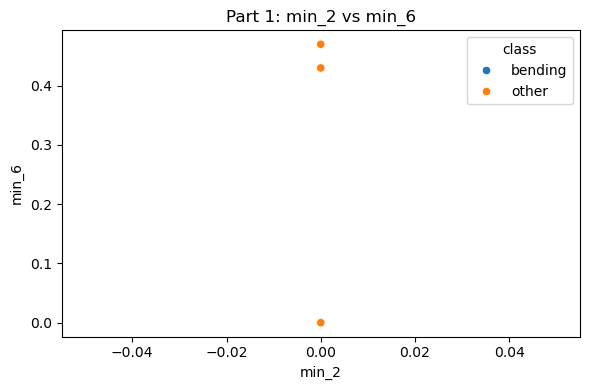

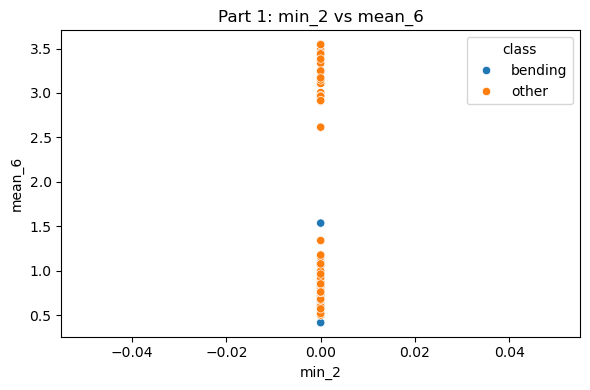

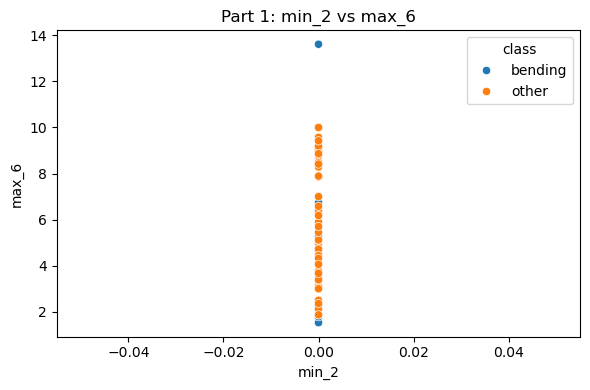

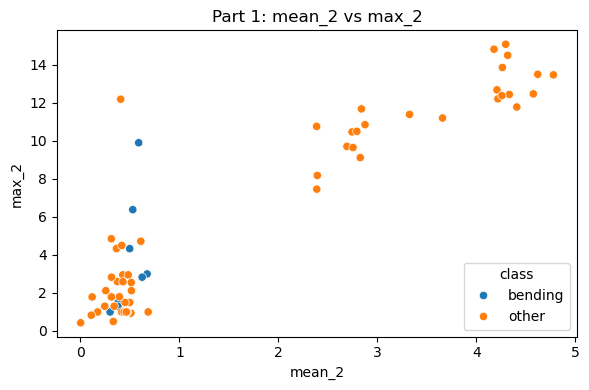

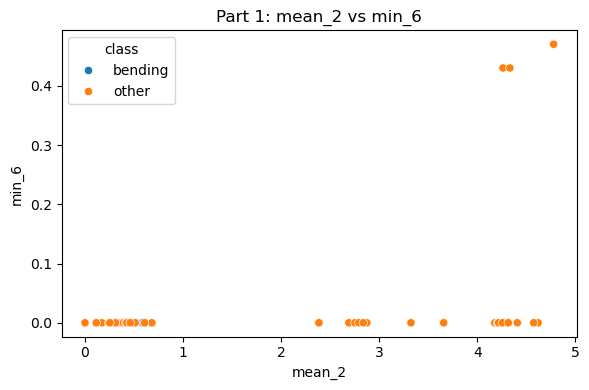

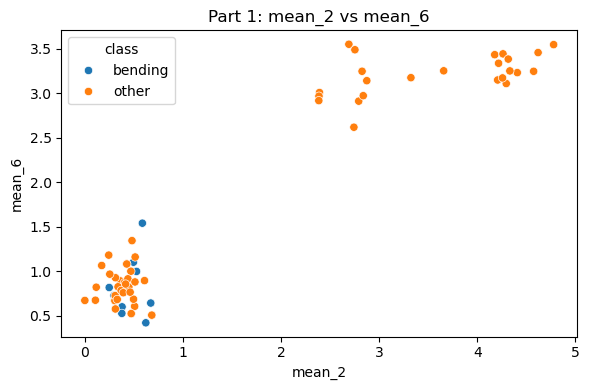

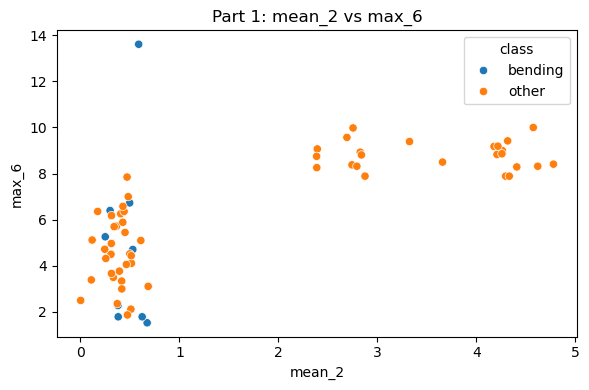

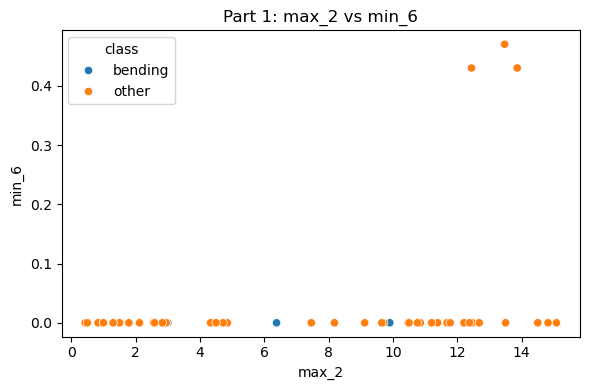

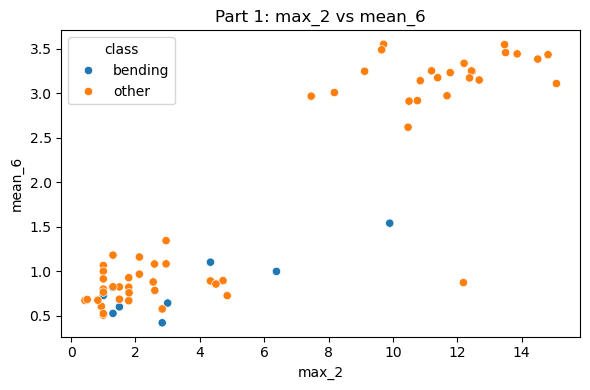

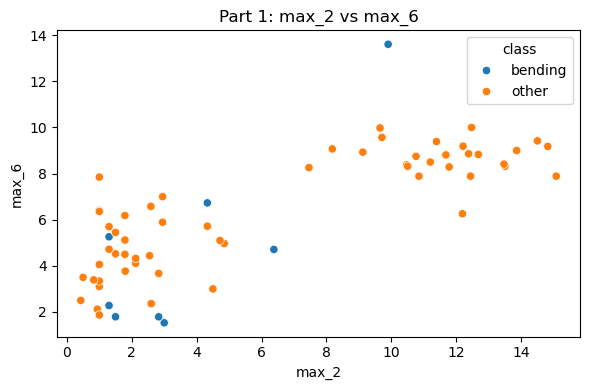

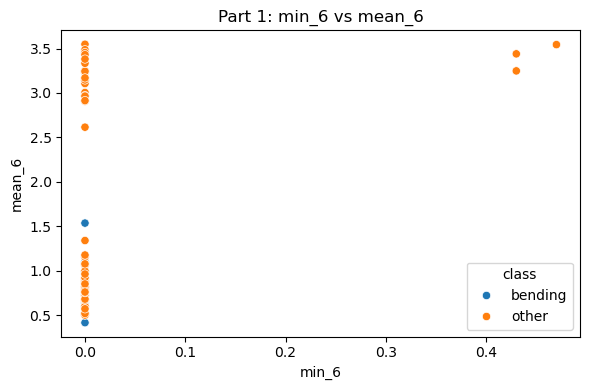

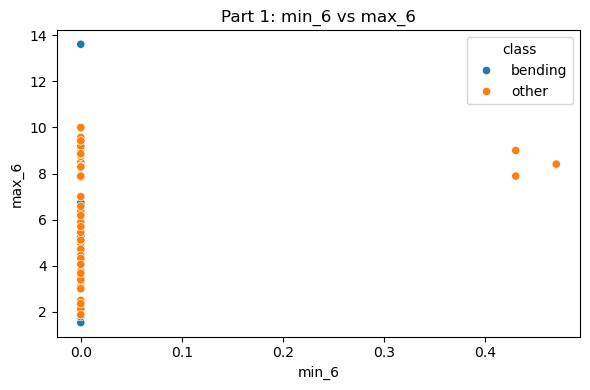

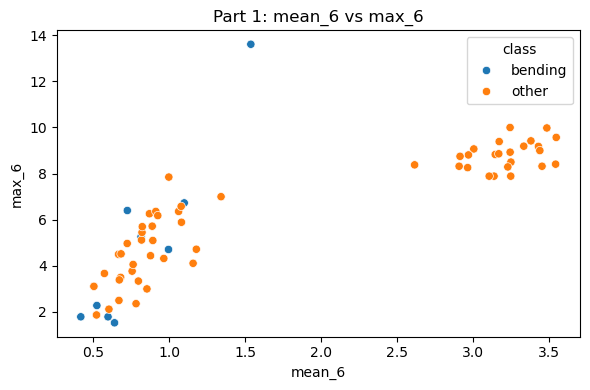

Scatter plots for part 2


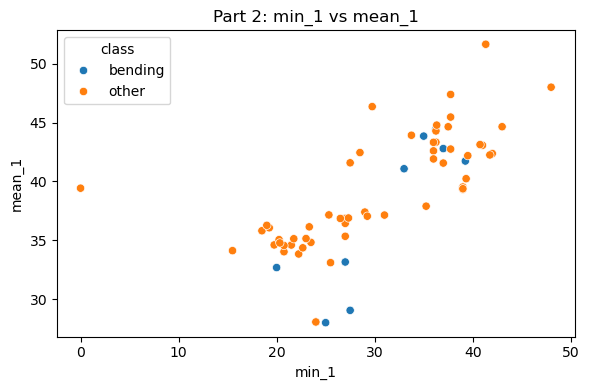

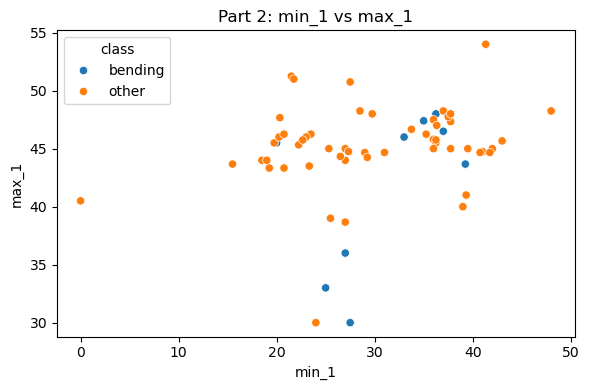

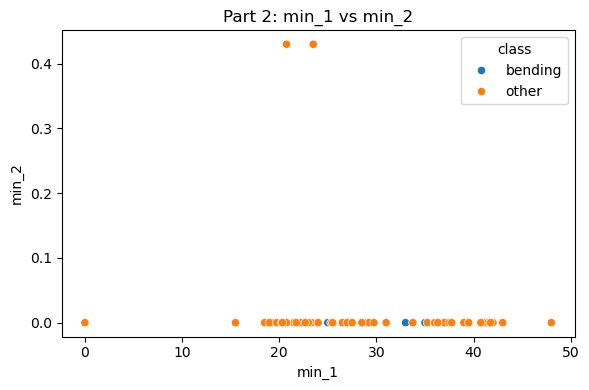

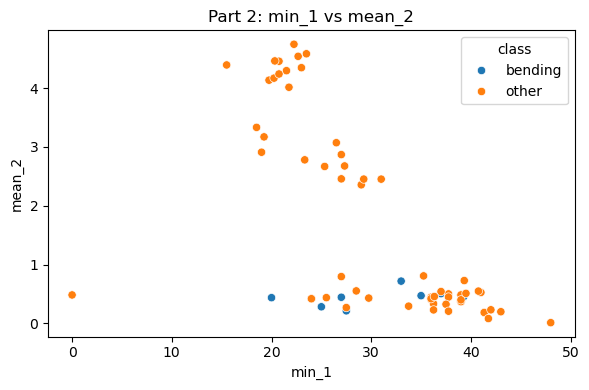

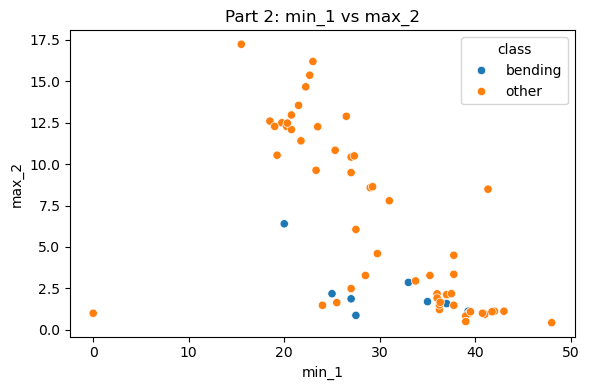

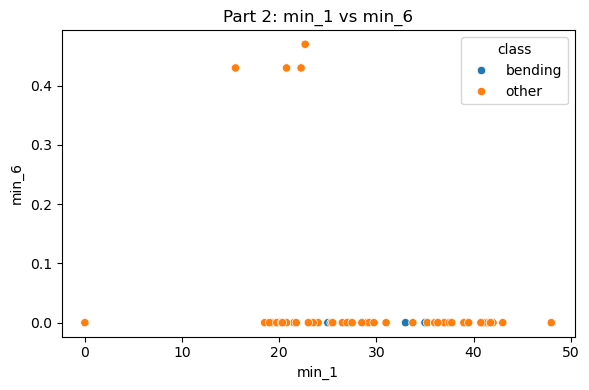

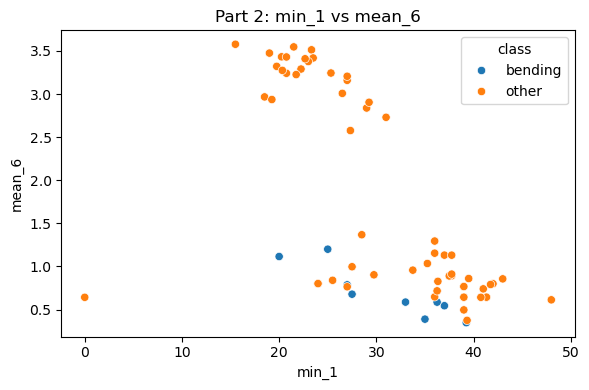

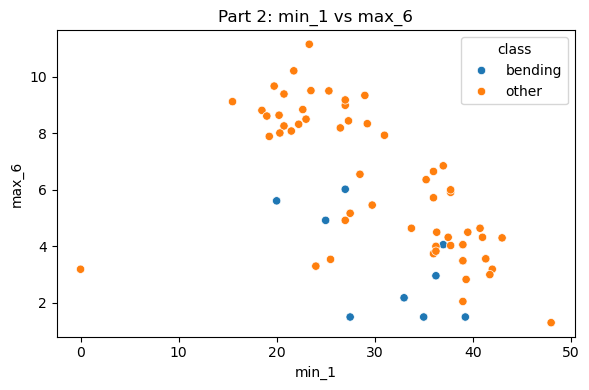

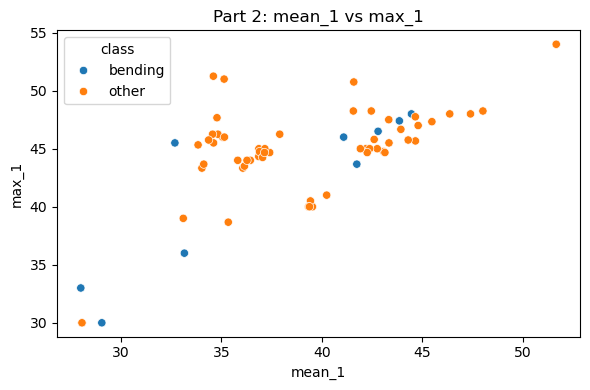

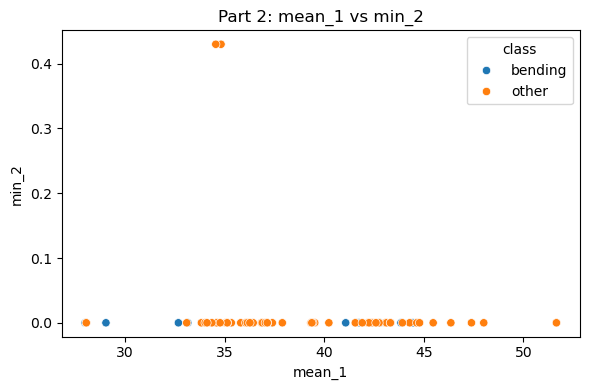

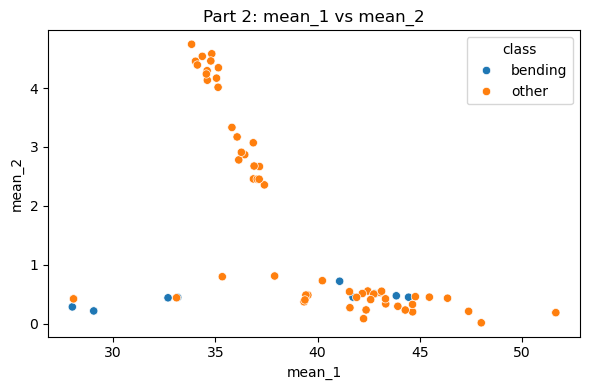

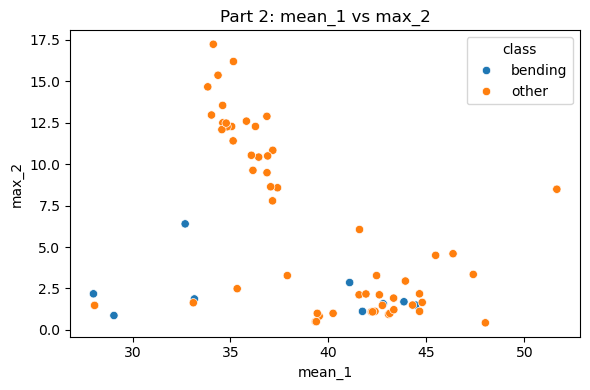

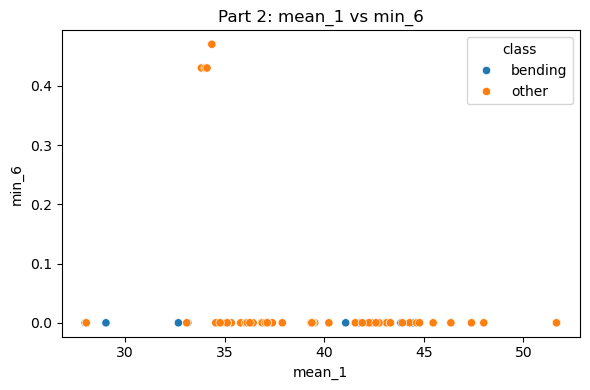

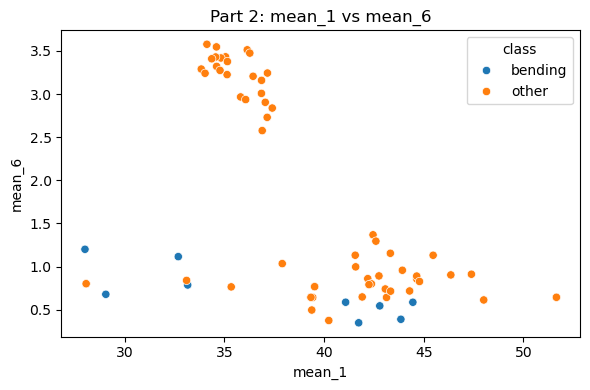

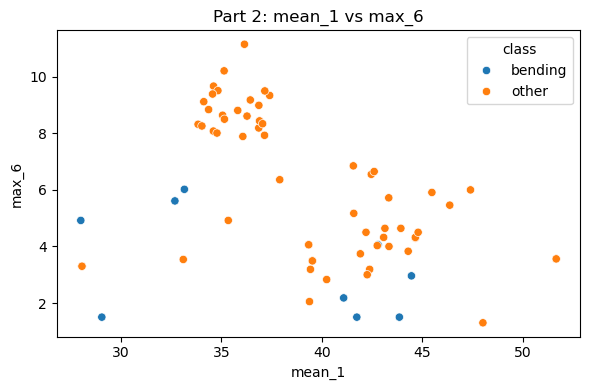

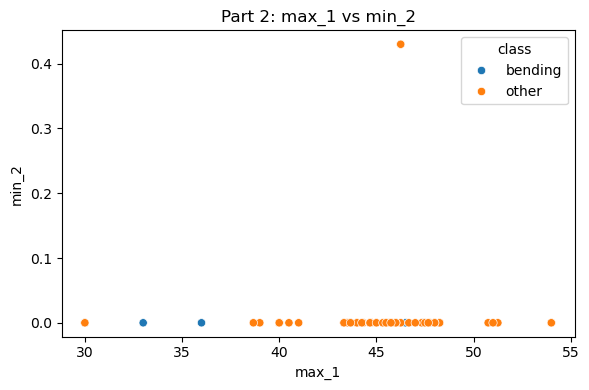

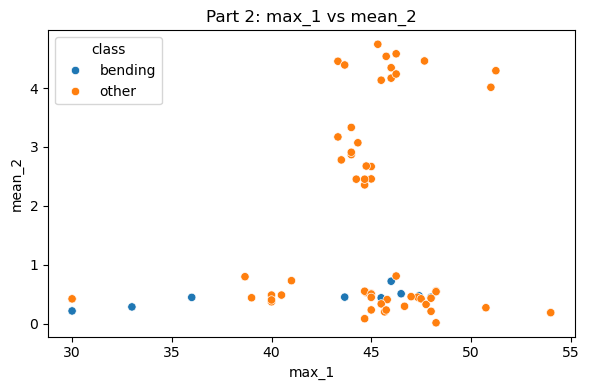

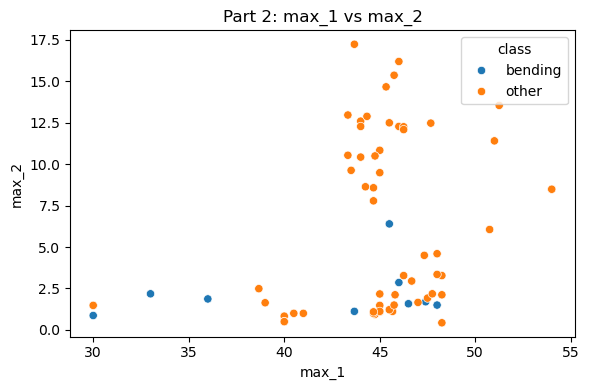

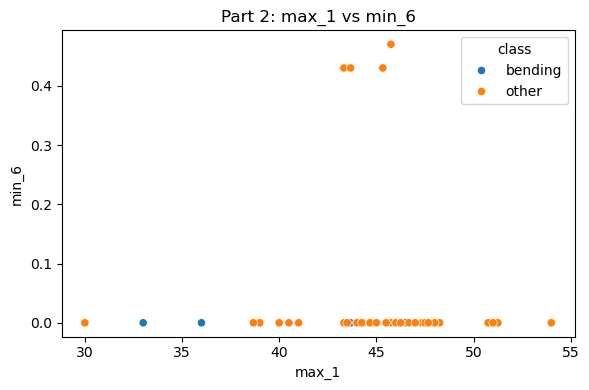

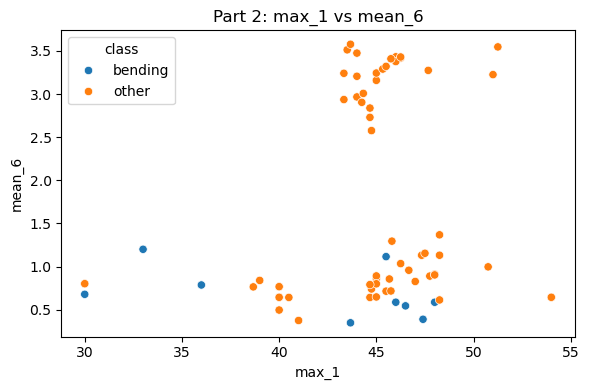

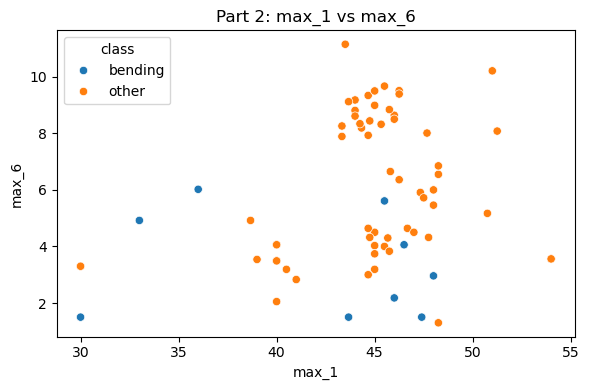

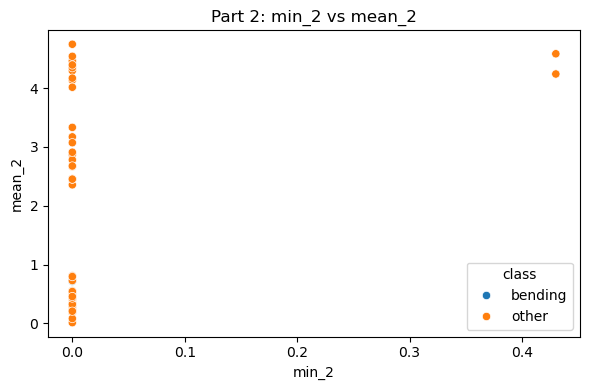

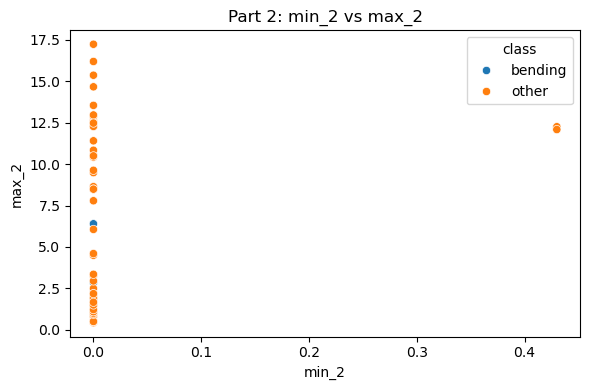

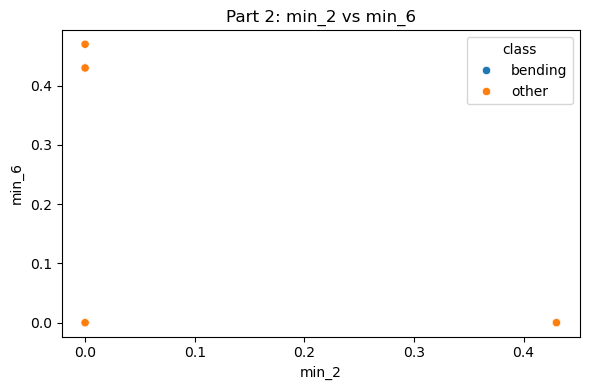

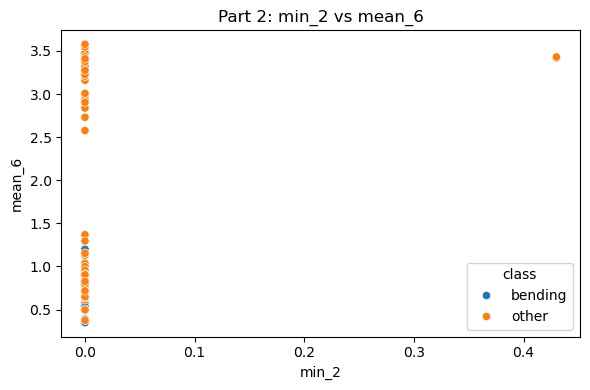

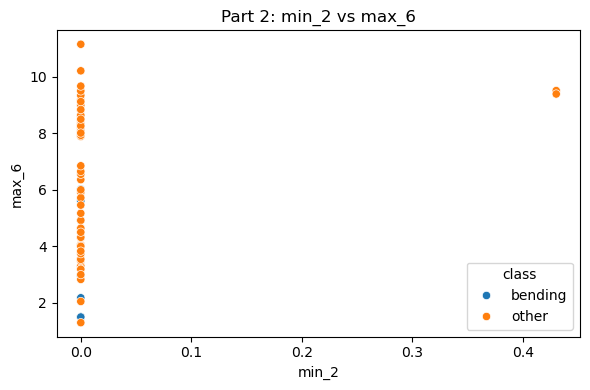

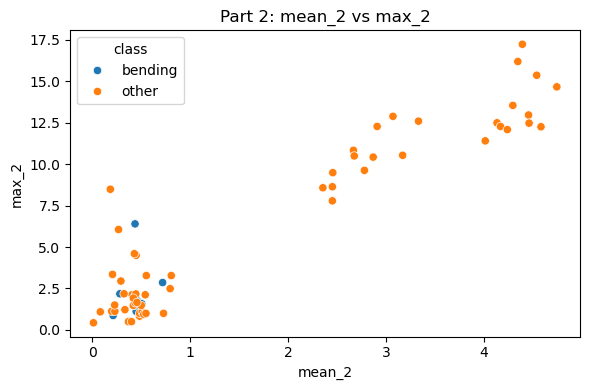

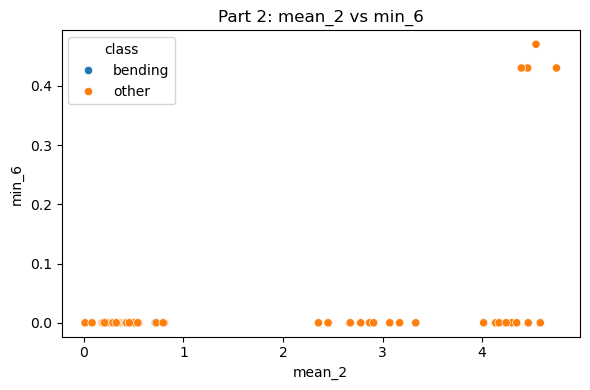

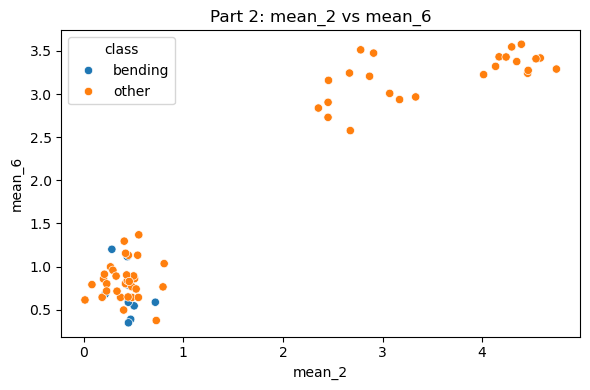

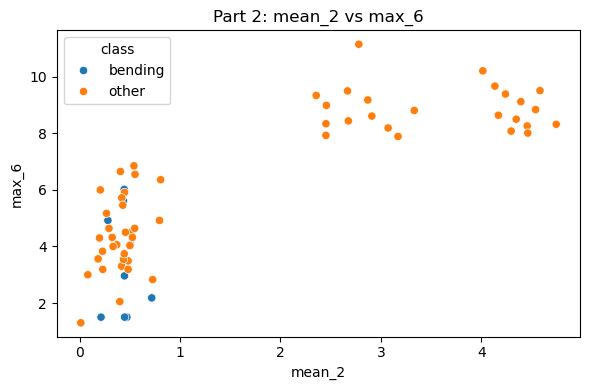

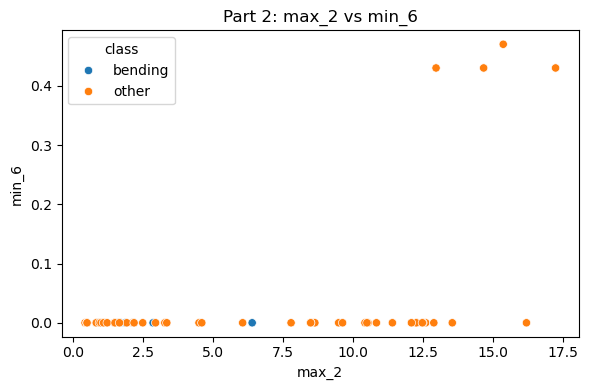

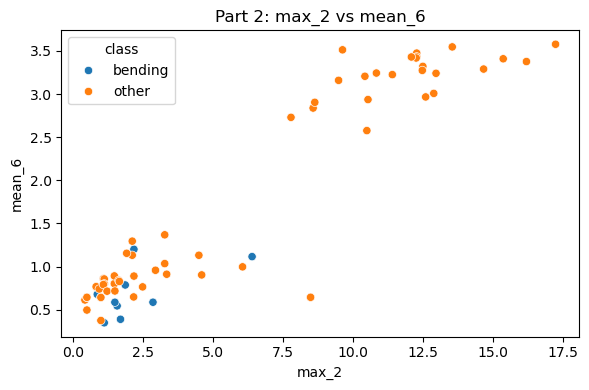

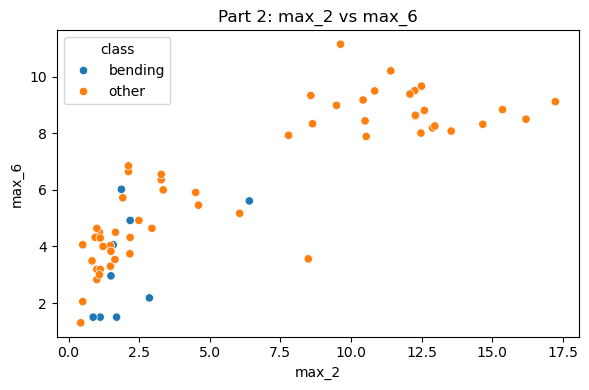

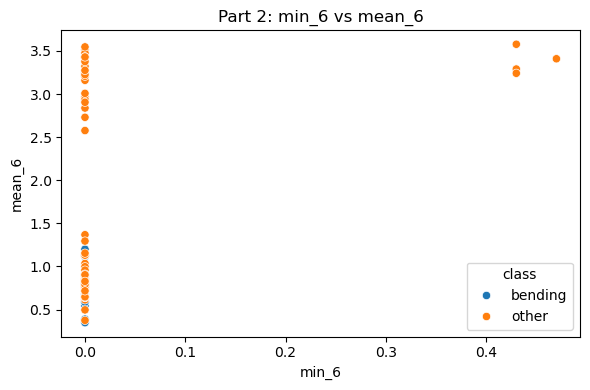

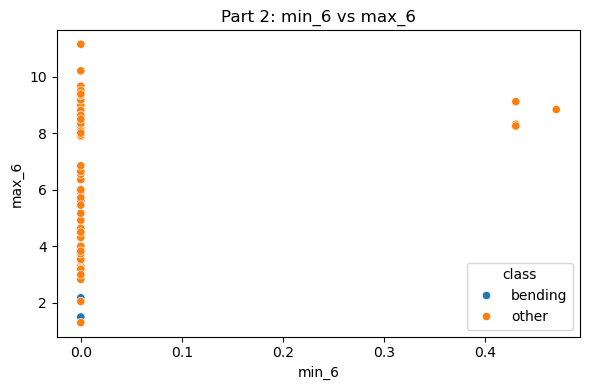

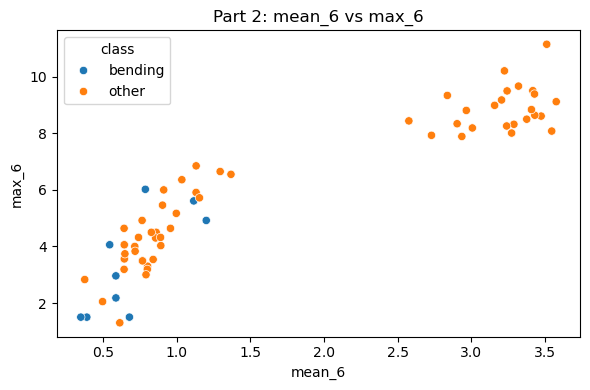

In [65]:
sensor_columns = [
    "avg_rss12", "var_rss12",
    "avg_rss13", "var_rss13",
    "avg_rss23", "var_rss23"
]

split_features = []

for file_path in train_files:
    activity = os.path.basename(os.path.dirname(file_path))
    filename = os.path.basename(file_path).replace(".csv", "")

    #read the time series
    if activity == "bending2" and filename == "dataset4":
        df = pd.read_csv(file_path, skiprows=5, sep=r"\s+", header=None)
        df.columns = [
            "time", "avg_rss12", "var_rss12",
            "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"
        ]
    else:
        df = pd.read_csv(file_path, skiprows=4, usecols=range(7))

    #2 parts
    midpoint = len(df) // 2
    parts = [df.iloc[:midpoint], df.iloc[midpoint:]]

    for part_number, part in enumerate(parts, start=1):
        row = {
            "instance": activity + "_" + filename,
            "part": part_number,
            "class": "bending" if activity in ["bending1", "bending2"] else "other"
        }

        #minimum mean and maximum
        for i in [1, 2, 6]:
            column = sensor_columns[i - 1]
            row[f"min_{i}"] = part[column].min()
            row[f"mean_{i}"] = part[column].mean()
            row[f"max_{i}"] = part[column].max()

        split_features.append(row)

split_df = pd.DataFrame(split_features)

print("Dataset shape:", split_df.shape)
print(split_df.head())


features = [
    "min_1", "mean_1", "max_1",
    "min_2", "mean_2", "max_2",
    "min_6", "mean_6", "max_6"
]

for part_number in [1, 2]:
    part_df = split_df[split_df["part"] == part_number]

    print("Scatter plots for part", part_number)

    for i in range(len(features)):
        for j in range(i + 1, len(features)):
            plt.figure(figsize=(6, 4))

            sns.scatterplot(
                data=part_df,
                x=features[i],
                y=features[j],
                hue="class"
            )

            plt.title(
                "Part " + str(part_number) + ": "
                + features[i] + " vs " + features[j]
            )
            plt.tight_layout()
            plt.show()


By splitting each training time series into two approximately equal parts, I obtained two sets of features for each original instance. I then plotted the minimum, mean, and maximum features from time series 1, 2, and 6. I noticed that this set of scatterplots are a lot more scattered out compared to part a, where both the points from the bending and other class were more clustered together. This suggests that the sensor measurements vary between the first and second halves of each activity.

#### iii. Time Series Segments

In [66]:
#6 sensor measurements
sensor_columns = [
    "avg_rss12", "var_rss12",
    "avg_rss13", "var_rss13",
    "avg_rss23", "var_rss23"
]

#original training instances
instances = []

for file_path in train_files:
    activity = os.path.basename(os.path.dirname(file_path))
    filename = os.path.basename(file_path).replace(".csv", "")

    if activity == "bending2" and filename == "dataset4":
        df = pd.read_csv(
            file_path, skiprows=5, sep=r"\s+", header=None
        )
        df.columns = [
            "time", "avg_rss12", "var_rss12",
            "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"
        ]
    else:
        df = pd.read_csv(
            file_path, skiprows=4, usecols=range(7)
        )

    instances.append({
        "instance": activity + "_" + filename,
        "class": 1 if activity in ["bending1", "bending2"] else 0,
        "data": df
    })

#5 fold cross validation
cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

#candidate numbers
p_candidates = [1, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50]

results = []

#1 to 20
for l in range(1, 21):
    rows = []

    for instance in instances:
        df = instance["data"]
        segments = [
            df.iloc[i * len(df) // l:(i + 1) * len(df) // l]
            for i in range(l)
            ]

        row = {
            "class": instance["class"]
        }

        for segment_number, segment in enumerate(segments, start=1):
            for column_number, column in enumerate(sensor_columns, start=1):
                values = segment[column]

                row[f"segment{segment_number}_min_{column_number}"] = values.min()
                row[f"segment{segment_number}_max_{column_number}"] = values.max()
                row[f"segment{segment_number}_mean_{column_number}"] = values.mean()
                row[f"segment{segment_number}_median_{column_number}"] = values.median()
                row[f"segment{segment_number}_std_{column_number}"] = values.std()
                row[f"segment{segment_number}_q1_{column_number}"] = values.quantile(0.25)
                row[f"segment{segment_number}_q3_{column_number}"] = values.quantile(0.75)

        rows.append(row)

    feature_df = pd.DataFrame(rows)

    X = feature_df.drop(columns=["class"])
    y = feature_df["class"]

    #p values that do not exceed the number of features
    p_values = [p for p in p_candidates if p <= X.shape[1]]

    #fit logistic regression
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("rfe", RFE(
            estimator=LogisticRegression(
                max_iter=5000,
                class_weight="balanced"
            ),
            step=0.1
        )),
        ("logistic", LogisticRegression(
            max_iter=5000,
            class_weight="balanced"
        ))
    ])

    search = GridSearchCV(
        estimator=model,
        param_grid={
            "rfe__n_features_to_select": p_values
        },
        scoring="f1",
        cv=cv,
        n_jobs=-1
    )

    search.fit(X, y)

    results.append({
        "l": l,
        "p": search.best_params_["rfe__n_features_to_select"],
        "F1 Score": search.best_score_
    })

    print(
        "l =", l,
        "Best p =", search.best_params_["rfe__n_features_to_select"],
        "Mean CV F1 =", round(search.best_score_, 4)
    )

results_df = pd.DataFrame(results)
print(results_df, "\n")

#highest F1 score
best = results_df.loc[results_df["F1 Score"].idxmax()]

print("\nBest combination:")
print("l =", int(best["l"]))
print("p =", int(best["p"]))
print("F1 Score =", round(best["F1 Score"], 4))


l = 1 Best p = 5 Mean CV F1 = 0.8667
l = 2 Best p = 20 Mean CV F1 = 0.7867
l = 3 Best p = 15 Mean CV F1 = 0.7867
l = 4 Best p = 30 Mean CV F1 = 0.7933
l = 5 Best p = 20 Mean CV F1 = 0.7933
l = 6 Best p = 35 Mean CV F1 = 0.8933
l = 7 Best p = 35 Mean CV F1 = 0.8933
l = 8 Best p = 20 Mean CV F1 = 0.76
l = 9 Best p = 40 Mean CV F1 = 0.8933
l = 10 Best p = 30 Mean CV F1 = 0.7933
l = 11 Best p = 1 Mean CV F1 = 0.8267
l = 12 Best p = 1 Mean CV F1 = 0.8933
l = 13 Best p = 40 Mean CV F1 = 0.8267
l = 14 Best p = 20 Mean CV F1 = 0.8267
l = 15 Best p = 20 Mean CV F1 = 0.76
l = 16 Best p = 25 Mean CV F1 = 0.7933
l = 17 Best p = 15 Mean CV F1 = 0.8267
l = 18 Best p = 5 Mean CV F1 = 0.8933
l = 19 Best p = 30 Mean CV F1 = 0.8267
l = 20 Best p = 5 Mean CV F1 = 0.8267
     l   p  F1 Score
0    1   5  0.866667
1    2  20  0.786667
2    3  15  0.786667
3    4  30  0.793333
4    5  20  0.793333
5    6  35  0.893333
6    7  35  0.893333
7    8  20  0.760000
8    9  40  0.893333
9   10  30  0.793333
10  11 

The highest mean cross validation F1 score was 0.8933 with the 4 combinations(l,p)=(6,35),(7,35),(9,40), and (12,1). The combination (12,1) uses only one feature and gives the same cross validation score as the models using more features, making it the best choice of models. 

#### iv. Confusion Matrix

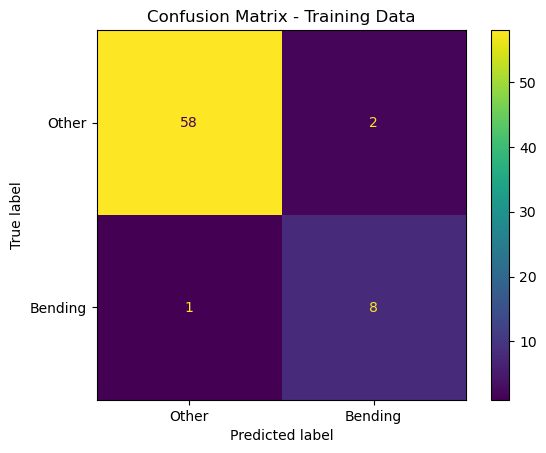

              precision    recall  f1-score   support

       Other       0.98      0.97      0.97        60
     Bending       0.80      0.89      0.84         9

    accuracy                           0.96        69
   macro avg       0.89      0.93      0.91        69
weighted avg       0.96      0.96      0.96        69



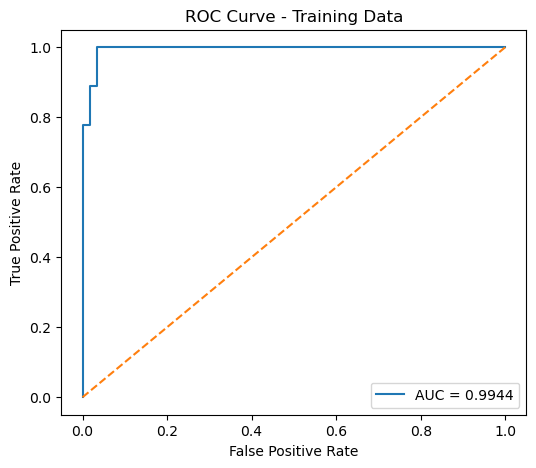

Training AUC: 0.9944
Optimization terminated successfully.
         Current function value: 0.053069
         Iterations 11
                           Logit Regression Results                           
Dep. Variable:                  class   No. Observations:                   69
Model:                          Logit   Df Residuals:                       67
Method:                           MLE   Df Model:                            1
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                  0.8629
Time:                        17:30:02   Log-Likelihood:                -3.6618
converged:                       True   LL-Null:                       -26.718
Covariance Type:            nonrobust   LLR p-value:                 1.117e-11
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const           -26.2836     13.298     -1.976      0.048     -52.348      -0.21

In [67]:
l = 12
p = 1

rows = []

for instance in instances:
    df = instance["data"]
    segments = [
        df.iloc[i * len(df) // l:(i + 1) * len(df) // l]
        for i in range(l)
    ]

    row = {"class": instance["class"]}

    for segment_number, segment in enumerate(segments, start=1):
        for column_number, column in enumerate(sensor_columns, start=1):
            values = segment[column]

            row[f"segment{segment_number}_min_{column_number}"] = values.min()
            row[f"segment{segment_number}_max_{column_number}"] = values.max()
            row[f"segment{segment_number}_mean_{column_number}"] = values.mean()
            row[f"segment{segment_number}_median_{column_number}"] = values.median()
            row[f"segment{segment_number}_std_{column_number}"] = values.std()
            row[f"segment{segment_number}_q1_{column_number}"] = values.quantile(0.25)
            row[f"segment{segment_number}_q3_{column_number}"] = values.quantile(0.75)

    rows.append(row)

feature_df = pd.DataFrame(rows)

X = feature_df.drop(columns=["class"])
y = feature_df["class"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

rfe = RFE(
    estimator=LogisticRegression(max_iter=10000, class_weight="balanced"),
    n_features_to_select=p
)
rfe.fit(X_scaled, y)

selected_features = X.columns[rfe.support_]
X_selected = X[selected_features]

#fit logistic regression
final_scaler = StandardScaler()
X_selected_scaled = final_scaler.fit_transform(X_selected)

model = LogisticRegression(max_iter=10000, class_weight="balanced")
model.fit(X_selected_scaled, y)

#predictions on training data
y_pred = model.predict(X_selected_scaled)
y_prob = model.predict_proba(X_selected_scaled)[:, 1]

cm = confusion_matrix(y, y_pred, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Other", "Bending"]
).plot()

plt.title("Confusion Matrix - Training Data")
plt.show()

print(classification_report(
    y, y_pred,
    labels=[0, 1],
    target_names=["Other", "Bending"],
    zero_division=0
))

fpr, tpr, thresholds = roc_curve(y, y_prob)
auc = roc_auc_score(y, y_prob)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUC = {auc:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Training Data")
plt.legend()
plt.show()

print("Training AUC:", round(auc, 4))

X_stats = sm.add_constant(X_selected)

stats_model = sm.Logit(y, X_stats)
stats_results = stats_model.fit()

print(stats_results.summary())

#display coefficients and p-values in a table
coefficient_table = pd.DataFrame({
    "Coefficient (beta)": stats_results.params,
    "P-value": stats_results.pvalues
})

print(coefficient_table)

#### v. Test Classifier

In [68]:

l = 12
test_rows = []

for file_path in test_files:
    activity = os.path.basename(os.path.dirname(file_path))
    filename = os.path.basename(file_path).replace(".csv", "")

    #read the test time series
    if activity == "bending2" and filename == "dataset4":
        df = pd.read_csv(file_path, skiprows=5, sep=r"\s+", header=None)
        df.columns = [
            "time", "avg_rss12", "var_rss12",
            "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"
        ]
    else:
        df = pd.read_csv(file_path, skiprows=4, usecols=range(7))

    #divide each time series into 12
    segments = [
        df.iloc[i * len(df) // l:(i + 1) * len(df) // l]
        for i in range(l)
    ]

    row = {
        "instance": activity + "_" + filename,
        "class": 1 if activity in ["bending1", "bending2"] else 0
    }

    for segment_number, segment in enumerate(segments, start=1):
        for column_number, column in enumerate(sensor_columns, start=1):
            values = segment[column]

            row[f"segment{segment_number}_min_{column_number}"] = values.min()
            row[f"segment{segment_number}_max_{column_number}"] = values.max()
            row[f"segment{segment_number}_mean_{column_number}"] = values.mean()
            row[f"segment{segment_number}_median_{column_number}"] = values.median()
            row[f"segment{segment_number}_std_{column_number}"] = values.std()
            row[f"segment{segment_number}_q1_{column_number}"] = values.quantile(0.25)
            row[f"segment{segment_number}_q3_{column_number}"] = values.quantile(0.75)

    test_rows.append(row)

test_df = pd.DataFrame(test_rows)

#use the same feature selected from the training set
X_test = test_df[selected_features]
y_test = test_df["class"]

#scalar
X_test_scaled = final_scaler.transform(X_test)

y_test_pred = model.predict(X_test_scaled)

#find test accuracy
test_accuracy = accuracy_score(y_test, y_test_pred)
print("Test accuracy:", round(test_accuracy, 4))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_test_pred, labels=[0, 1]))

print("\nClassification report:")
print(classification_report(
    y_test, y_test_pred,
    labels=[0, 1],
    target_names=["Other", "Bending"],
    zero_division=0
))


print("Cross validation accuracy:", "0.96")
print("Test accuracy:", round(test_accuracy, 4))


Test accuracy: 0.8947

Confusion matrix:
[[14  1]
 [ 1  3]]

Classification report:
              precision    recall  f1-score   support

       Other       0.93      0.93      0.93        15
     Bending       0.75      0.75      0.75         4

    accuracy                           0.89        19
   macro avg       0.84      0.84      0.84        19
weighted avg       0.89      0.89      0.89        19

Cross validation accuracy: 0.96
Test accuracy: 0.8947


#### vi. Separation

Yes, the two classes seem to be well separated and cause instability in estimating the logistic regression parameters. This means that the selected feature, segment2_q1_5, can distinguish bending activities from other activities very effectively. This is supported by the high training AUC of 0.9944. The pseudo r ^2 of 0.8629 also indicates that the model fits the training data better than a model containing only an intercept. However, the model produced a warning about possible quasi-separation, meaning that some observations can be predicted based on the selected feature. With the test accuracy of 89.47, the results suggest that the feature is useful for finding the classes, but the quasi-separation warning should be looked into.

#### vii. Imbalance

Yes, there is imbalanced classes within the confusion matrix obtained.

Balanced class counts:
Other: 60
Bending: 60

Confusion matrix:
[[15  0]
 [ 1  3]]

Classification report:
              precision    recall  f1-score   support

       Other       0.94      1.00      0.97        15
     Bending       1.00      0.75      0.86         4

    accuracy                           0.95        19
   macro avg       0.97      0.88      0.91        19
weighted avg       0.95      0.95      0.94        19

Test accuracy: 0.9473684210526315


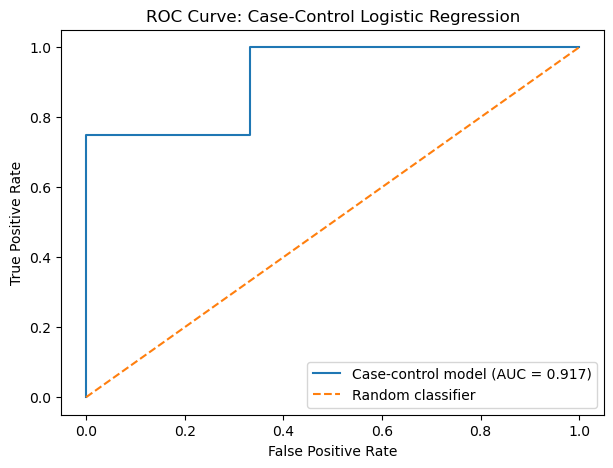

Test AUC: 0.9166666666666667


In [69]:
#select feature
feature_name = "segment2_q1_5"

X_train_selected = X[[feature_name]]
X_test_selected = X_test[[feature_name]]

#scale features using the training data
case_control_scaler = StandardScaler()
X_train_scaled = case_control_scaler.fit_transform(X_train_selected)
X_test_scaled = case_control_scaler.transform(X_test_selected)

#separate the two classes in the training data
other = X_train_scaled[np.array(y) == 0]
bending = X_train_scaled[np.array(y) == 1]

#oversample Bending
bending_oversampled = resample(
    bending,
    replace=True,
    n_samples=len(other),
    random_state=42
)

#balanced training set
X_balanced = np.vstack((other, bending_oversampled))
y_balanced = np.concatenate((
    np.zeros(len(other), dtype=int),
    np.ones(len(bending_oversampled), dtype=int)
))

print("Balanced class counts:")
print("Other:", sum(y_balanced == 0))
print("Bending:", sum(y_balanced == 1))

#logistic regression
case_control_model = LogisticRegression(max_iter=10000)
case_control_model.fit(X_balanced, y_balanced)

test_scores = case_control_model.decision_function(X_test_scaled)

original_prevalence = np.mean(np.array(y) == 1)
sample_prevalence = np.mean(y_balanced == 1)

intercept_adjustment = (
    np.log(original_prevalence / (1 - original_prevalence))
    - np.log(sample_prevalence / (1 - sample_prevalence))
)

adjusted_scores = test_scores + intercept_adjustment
adjusted_probabilities = expit(adjusted_scores)

#predict classes
y_pred_case_control = (adjusted_probabilities >= 0.5).astype(int)

#confusion matrix
cm_case_control = confusion_matrix(y_test, y_pred_case_control)
print("\nConfusion matrix:")
print(cm_case_control)

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred_case_control,
    target_names=["Other", "Bending"],
    zero_division=0
))

print("Test accuracy:", accuracy_score(y_test, y_pred_case_control))

#rOC curve and AUC
fpr_cc, tpr_cc, thresholds_cc = roc_curve(
    y_test, adjusted_probabilities
)
auc_cc = roc_auc_score(y_test, adjusted_probabilities)

plt.figure(figsize=(7, 5))
plt.plot(fpr_cc, tpr_cc, label=f"Case-control model (AUC = {auc_cc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: Case-Control Logistic Regression")
plt.legend()
plt.show()

print("Test AUC:", auc_cc)

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [70]:

def make_feature_df(files, l):
    rows = []

    sensor_columns = [
        "avg_rss12", "var_rss12",
        "avg_rss13", "var_rss13",
        "avg_rss23", "var_rss23"
    ]

    for file_path in files:

        if "bending2/dataset4.csv" in file_path.replace("\\", "/"):
            df = pd.read_csv(
                file_path,
                sep=r"\s+",
                skiprows=5,
                header=None,
                engine="python"
            )

            #keep the six sensor columns
            df = df.iloc[:, -6:]
            df.columns = sensor_columns

        else:
            df = pd.read_csv(
                file_path,
                skiprows=4,
                usecols=range(1, 7),
                engine="python"
            )
            df.columns = sensor_columns

        #divide the time series into l segments
        segments = [
            df.iloc[i * len(df) // l:(i + 1) * len(df) // l]
            for i in range(l)
        ]

        row = {}

        for segment_number, segment in enumerate(segments, start=1):
            for column_number, column in enumerate(sensor_columns, start=1):
                values = segment[column]

                row[f"min_{segment_number}_{column_number}"] = values.min()
                row[f"max_{segment_number}_{column_number}"] = values.max()
                row[f"mean_{segment_number}_{column_number}"] = values.mean()
                row[f"median_{segment_number}_{column_number}"] = values.median()
                row[f"std_{segment_number}_{column_number}"] = values.std()
                row[f"q1_{segment_number}_{column_number}"] = values.quantile(0.25)
                row[f"q3_{segment_number}_{column_number}"] = values.quantile(0.75)

        normalized_path = file_path.replace("\\", "/")

        if "/bending1/" in normalized_path or "/bending2/" in normalized_path:
            row["class"] = 1
        else:
            row["class"] = 0

        rows.append(row)

    return pd.DataFrame(rows)

test_features = make_feature_df(train_files, 1)
print(test_features.shape)
print(test_features["class"].value_counts())

(69, 43)
class
0    60
1     9
Name: count, dtype: int64


In [71]:
C_values = [0.001, 0.01, 0.1, 1, 10, 100]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results_l1 = []

for l in range(1, 21):
    train_features_l = make_feature_df(train_files, l)

    X_train_l = train_features_l.drop(columns=["class"])
    y_train_l = train_features_l["class"]

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(
            penalty="l1",
            solver="liblinear",
            max_iter=10000,
            random_state=42
        ))
    ])

    search = GridSearchCV(
        pipeline,
        {"logistic__C": C_values},
        scoring="f1",
        cv=cv,
        n_jobs=-1
    )

    search.fit(X_train_l, y_train_l)

    results_l1.append({
        "l": l,
        "C": search.best_params_["logistic__C"],
        "CV F1": search.best_score_,
        "model": search.best_estimator_
    })

    print(
        f"l={l}, C={search.best_params_['logistic__C']}, "
        f"CV F1={search.best_score_:.4f}"
    )

results_l1_df = pd.DataFrame([
    {"l": r["l"], "C": r["C"], "CV F1": r["CV F1"]}
    for r in results_l1
])

print(results_l1_df)

best_result = max(results_l1, key=lambda r: r["CV F1"])

print("Best l:", best_result["l"])
print("Best C:", best_result["C"])
print("Best CV F1:", best_result["CV F1"])

l=1, C=10, CV F1=0.8533
l=2, C=10, CV F1=0.8933
l=3, C=1, CV F1=0.8267
l=4, C=100, CV F1=0.7867
l=5, C=100, CV F1=0.6267
l=6, C=10, CV F1=0.8533
l=7, C=100, CV F1=0.6933
l=8, C=100, CV F1=0.6933
l=9, C=10, CV F1=0.6533
l=10, C=100, CV F1=0.8933
l=11, C=1, CV F1=0.7600
l=12, C=1, CV F1=0.8933
l=13, C=100, CV F1=0.8933
l=14, C=10, CV F1=0.8267
l=15, C=10, CV F1=0.6267
l=16, C=100, CV F1=0.7933
l=17, C=1, CV F1=0.6933
l=18, C=100, CV F1=0.8933
l=19, C=10, CV F1=0.8267
l=20, C=10, CV F1=0.8267
     l    C     CV F1
0    1   10  0.853333
1    2   10  0.893333
2    3    1  0.826667
3    4  100  0.786667
4    5  100  0.626667
5    6   10  0.853333
6    7  100  0.693333
7    8  100  0.693333
8    9   10  0.653333
9   10  100  0.893333
10  11    1  0.760000
11  12    1  0.893333
12  13  100  0.893333
13  14   10  0.826667
14  15   10  0.626667
15  16  100  0.793333
16  17    1  0.693333
17  18  100  0.893333
18  19   10  0.826667
19  20   10  0.826667
Best l: 2
Best C: 10
Best CV F1: 0.89333333

In [72]:
# Get the best model and number of segments
best_l = best_result["l"]
best_model = best_result["model"]

# Create test features using the same number of segments
test_features_l = make_feature_df(test_files, best_l)

X_test_l = test_features_l.drop(columns=["class"])
y_test_l = test_features_l["class"]

# Predict the classes and probabilities
y_pred_l1 = best_model.predict(X_test_l)
y_prob_l1 = best_model.predict_proba(X_test_l)[:, 1]

# Confusion matrix
print("Best l:", best_l)
print("Best C:", best_result["C"])

print("\nConfusion matrix:")
print(confusion_matrix(y_test_l, y_pred_l1))

print("\nClassification report:")
print(classification_report(
    y_test_l,
    y_pred_l1,
    target_names=["Other", "Bending"],
    zero_division=0
))

print("Test accuracy:", accuracy_score(y_test_l, y_pred_l1))

# ROC curve and AUC
fpr_l1, tpr_l1, thresholds_l1 = roc_curve(y_test_l, y_prob_l1)
auc_l1 = roc_auc_score(y_test_l, y_prob_l1)

print("Test AUC:", auc_l1)


Best l: 2
Best C: 10

Confusion matrix:
[[15  0]
 [ 1  3]]

Classification report:
              precision    recall  f1-score   support

       Other       0.94      1.00      0.97        15
     Bending       1.00      0.75      0.86         4

    accuracy                           0.95        19
   macro avg       0.97      0.88      0.91        19
weighted avg       0.95      0.95      0.94        19

Test accuracy: 0.9473684210526315
Test AUC: 1.0


#### ii. Comparison

The L1 penalized logistic regression and the p-value based model achieved the same highest cross validation F1 score of 0.8933. However, the L1 model achieved a test accuracy of 94.74% compared to the 89.47% accuracy for the p-value model. The L1 model also achieved a test AUC of 1.00, showing that the L1 model performed better based on the observed test results. L1-penalized logistic regression is easier to implement because the model automatically selects important features through regularization, where the p-value model approach doesnt and requries additional feature selection steps.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

In [73]:
def make_multiclass_feature_df(files, l):
    rows = []

    sensor_columns = [
        "avg_rss12", "var_rss12",
        "avg_rss13", "var_rss13",
        "avg_rss23", "var_rss23"
    ]

    for file_path in files:
        normalized_path = file_path.replace("\\", "/")
        folder = normalized_path.split("/")[-2]

        #read AReM file
        if "bending2/dataset4.csv" in normalized_path:
            df = pd.read_csv(
                file_path,
                sep=r"\s+",
                skiprows=5,
                header=None,
                engine="python"
            )
            df = df.iloc[:, -6:]
            df.columns = sensor_columns
        else:
            df = pd.read_csv(
                file_path,
                skiprows=4,
                usecols=range(1, 7),
                engine="python"
            )
            df.columns = sensor_columns

        #two bending folders
        activity = "bending" if folder in ["bending1", "bending2"] else folder

        # Divide into l parts
        segments = [
            df.iloc[i * len(df) // l:(i + 1) * len(df) // l]
            for i in range(l)
        ]

        row = {}

        for segment_number, segment in enumerate(segments, start=1):
            for column_number, column in enumerate(sensor_columns, start=1):
                values = segment[column]

                row[f"min_{segment_number}_{column_number}"] = values.min()
                row[f"max_{segment_number}_{column_number}"] = values.max()
                row[f"mean_{segment_number}_{column_number}"] = values.mean()
                row[f"median_{segment_number}_{column_number}"] = values.median()
                row[f"std_{segment_number}_{column_number}"] = values.std()
                row[f"q1_{segment_number}_{column_number}"] = values.quantile(0.25)
                row[f"q3_{segment_number}_{column_number}"] = values.quantile(0.75)

        row["class"] = activity
        rows.append(row)

    return pd.DataFrame(rows)

check_df = make_multiclass_feature_df(train_files, 1)


from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
C_values = [0.001, 0.01, 0.1, 1, 10, 100]

l1_results = []

for l in range(1, 21):
    train_l = make_multiclass_feature_df(train_files, l)

    X_l = train_l.drop(columns=["class"])
    y_l = train_l["class"]

    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            penalty="l1",
            solver="saga",
            max_iter=20000,
            random_state=42
        ))
    ])

    search = GridSearchCV(
        pipe,
        {"model__C": C_values},
        scoring="f1_macro",
        cv=cv,
        n_jobs=-1
    )

    search.fit(X_l, y_l)

    l1_results.append({
        "l": l,
        "C": search.best_params_["model__C"],
        "CV_macro_F1": search.best_score_,
        "model": search.best_estimator_
    })

    print(
        f"l={l}, C={search.best_params_['model__C']}, "
        f"macro F1={search.best_score_:.3f}"
    )

best_l1 = max(l1_results, key=lambda r: r["CV_macro_F1"])

print("Best l:", best_l1["l"])
print("Best C:", best_l1["C"])
print("Best CV macro F1:", best_l1["CV_macro_F1"])



l=1, C=10, macro F1=0.898
l=2, C=1, macro F1=0.899
l=3, C=10, macro F1=0.899
l=4, C=10, macro F1=0.909
l=5, C=100, macro F1=0.908
l=6, C=100, macro F1=0.854
l=7, C=100, macro F1=0.822
l=8, C=100, macro F1=0.832
l=9, C=100, macro F1=0.825
l=10, C=10, macro F1=0.808
l=11, C=100, macro F1=0.746
l=12, C=100, macro F1=0.807
l=13, C=100, macro F1=0.773
l=14, C=100, macro F1=0.784
l=15, C=100, macro F1=0.762
l=16, C=100, macro F1=0.782
l=17, C=100, macro F1=0.769
l=18, C=10, macro F1=0.829
l=19, C=10, macro F1=0.820
l=20, C=100, macro F1=0.790
Best l: 4
Best C: 10
Best CV macro F1: 0.9094444444444445


Test accuracy: 0.8947368421052632
Test error: 0.10526315789473684


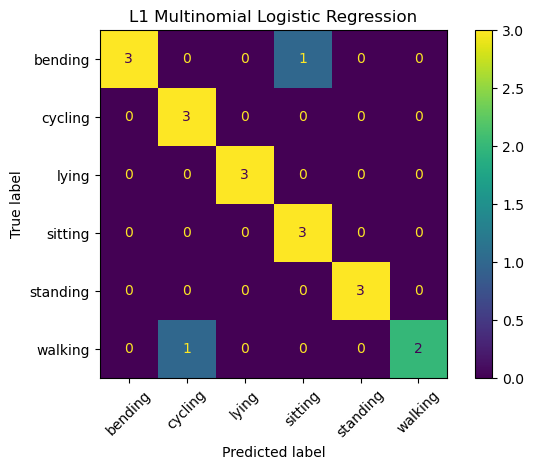

              precision    recall  f1-score   support

     bending       1.00      0.75      0.86         4
     cycling       0.75      1.00      0.86         3
       lying       1.00      1.00      1.00         3
     sitting       0.75      1.00      0.86         3
    standing       1.00      1.00      1.00         3
     walking       1.00      0.67      0.80         3

    accuracy                           0.89        19
   macro avg       0.92      0.90      0.90        19
weighted avg       0.92      0.89      0.89        19



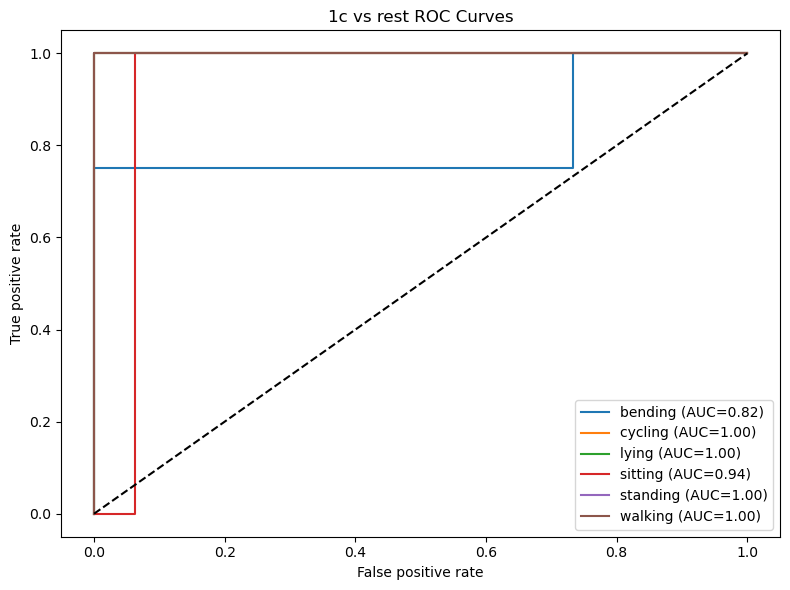

Macro 1c vs rest AUC: 0.9590277777777777


In [75]:
from sklearn.metrics import auc

best_l = best_l1["l"]
best_model = best_l1["model"]

test_l = make_multiclass_feature_df(test_files, best_l)
X_test_l = test_l.drop(columns=["class"])
y_test_l = test_l["class"]

y_pred = best_model.predict(X_test_l)
y_prob = best_model.predict_proba(X_test_l)

classes = best_model.named_steps["model"].classes_

# Test error
test_accuracy = accuracy_score(y_test_l, y_pred)
print("Test accuracy:", test_accuracy)
print("Test error:", 1 - test_accuracy)

#confusion matrix
cm = confusion_matrix(y_test_l, y_pred, labels=classes)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)
display.plot(xticks_rotation=45)
plt.title("L1 Multinomial Logistic Regression")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test_l, y_pred, labels=classes, zero_division=0
))

#roc
y_test_binary = label_binarize(y_test_l, classes=classes)

plt.figure(figsize=(8, 6))

for i, activity in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_test_binary[:, i], y_prob[:, i])
    class_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{activity} (AUC={class_auc:.2f})")

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("1c vs rest ROC Curves")
plt.legend()
plt.tight_layout()
plt.show()

print(
    "Macro 1c vs rest AUC:",
    roc_auc_score(
        y_test_binary,
        y_prob,
        average="macro",
        multi_class="ovr"
    )
)


#### ii. Naive Bayes

In [78]:
#store results for both classifiers
nb_results = []

for method in ["Gaussian", "Multinomial"]:
    for l in range(1, 21):
        train_l = make_multiclass_feature_df(train_files, l)

        X_l = train_l.drop(columns=["class"])
        y_l = train_l["class"]

        if method == "Gaussian":
            pipe = Pipeline([
                ("scaler", StandardScaler()),
                ("model", GaussianNB())
            ])
        else:
            pipe = Pipeline([
                ("scaler", MinMaxScaler()),
                ("model", MultinomialNB())
            ])

        scores = cross_val_score(
            pipe,
            X_l,
            y_l,
            cv=cv,
            scoring="f1_macro",
            n_jobs=-1
        )

        nb_results.append({
            "method": method,
            "l": l,
            "CV_macro_F1": scores.mean()
        })

    #print(f"Finished {method} Naive Bayes")

nb_results_df = pd.DataFrame(nb_results)

print(nb_results_df)

best_gaussian = (
    nb_results_df[nb_results_df["method"] == "Gaussian"]
    .sort_values("CV_macro_F1", ascending=False)
    .iloc[0]
)

best_multinomial = (
    nb_results_df[nb_results_df["method"] == "Multinomial"]
    .sort_values("CV_macro_F1", ascending=False)
    .iloc[0]
)

print("\nBest Gaussian l:", int(best_gaussian["l"]))
print("Gaussian CV macro F1:", best_gaussian["CV_macro_F1"])

print("\nBest Multinomial l:", int(best_multinomial["l"]))
print("Multinomial CV macro F1:", best_multinomial["CV_macro_F1"])


         method   l  CV_macro_F1
0      Gaussian   1     0.865000
1      Gaussian   2     0.793889
2      Gaussian   3     0.721111
3      Gaussian   4     0.717063
4      Gaussian   5     0.664603
5      Gaussian   6     0.657937
6      Gaussian   7     0.665714
7      Gaussian   8     0.732063
8      Gaussian   9     0.578492
9      Gaussian  10     0.604921
10     Gaussian  11     0.633016
11     Gaussian  12     0.647619
12     Gaussian  13     0.661111
13     Gaussian  14     0.524582
14     Gaussian  15     0.543492
15     Gaussian  16     0.581825
16     Gaussian  17     0.502915
17     Gaussian  18     0.451984
18     Gaussian  19     0.534185
19     Gaussian  20     0.522937
20  Multinomial   1     0.683254
21  Multinomial   2     0.729206
22  Multinomial   3     0.669921
23  Multinomial   4     0.651508
24  Multinomial   5     0.719603
25  Multinomial   6     0.703175
26  Multinomial   7     0.659497
27  Multinomial   8     0.704841
28  Multinomial   9     0.716164
29  Multin

In [76]:
def evaluate_nb(method, best_l):
    train_l = make_multiclass_feature_df(train_files, best_l)
    test_l = make_multiclass_feature_df(test_files, best_l)

    X_train_l = train_l.drop(columns=["class"])
    y_train_l = train_l["class"]

    X_test_l = test_l.drop(columns=["class"])
    y_test_l = test_l["class"]

    if method == "Gaussian":
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("model", GaussianNB())
        ])
    else:
        model = Pipeline([
            ("scaler", MinMaxScaler()),
            ("model", MultinomialNB())
        ])

    model.fit(X_train_l, y_train_l)
    predictions = model.predict(X_test_l)

    print(f"\n{method} Naive Bayes, l={best_l}")
    print("Test error:", 1 - accuracy_score(y_test_l, predictions))
    print("Confusion matrix:")
    print(confusion_matrix(y_test_l, predictions))
    print(classification_report(
        y_test_l, predictions, zero_division=0
    ))

    return model

gaussian_model = evaluate_nb(
    "Gaussian", int(best_gaussian["l"])
)

multinomial_model = evaluate_nb(
    "Multinomial", int(best_multinomial["l"])
)



Gaussian Naive Bayes, l=1
Test error: 0.10526315789473684
Confusion matrix:
[[4 0 0 0 0 0]
 [0 3 0 0 0 0]
 [1 0 2 0 0 0]
 [0 0 0 3 0 0]
 [0 0 0 1 2 0]
 [0 0 0 0 0 3]]
              precision    recall  f1-score   support

     bending       0.80      1.00      0.89         4
     cycling       1.00      1.00      1.00         3
       lying       1.00      0.67      0.80         3
     sitting       0.75      1.00      0.86         3
    standing       1.00      0.67      0.80         3
     walking       1.00      1.00      1.00         3

    accuracy                           0.89        19
   macro avg       0.92      0.89      0.89        19
weighted avg       0.92      0.89      0.89        19


Multinomial Naive Bayes, l=2
Test error: 0.1578947368421053
Confusion matrix:
[[4 0 0 0 0 0]
 [0 3 0 0 0 0]
 [0 1 2 0 0 0]
 [0 0 0 2 1 0]
 [0 0 0 1 2 0]
 [0 0 0 0 0 3]]
              precision    recall  f1-score   support

     bending       1.00      1.00      1.00         4
     cycli

#### ii. Comparison

The Gaussian Naive Bayes and the L1-penalized model performed better than Multinomial for the multiclass classification. Gaussian Naive Bayes achieved a test error of 10.53% with l=1 and a macro f1 score of 0.89, while Multinomial Naive Bayes achieved a test error of 15.79% using l=2 and a macro score of 0.83. However, the logistic regression achieved a slightly higher macro F1-score of 0.90 compared with 0.89 for Gaussian Naive Bayes.  Gaussian Naive Bayes performed well on the bending, cycling, sitting, and walking classes, while both methods had difficulty with the lying and standing classes from some other activities. Overall, the L1-penalized multinomial logistic regression is the strongest overall choice was the best of the three methods on the test set.

## 3. ISLR 4.8.3

To prove that the Bayes classifier is not linear but quadratic with K classes and an observation from the kth class we would need to use Bayes theorem. The Bayes classifier assigns an observation to the class with the highest posterior probability. Taking the log of the prior probability times the normal density gives an expression containing the log of the prior probability, the log of the standard deviation, and the squared difference between the observation and the class mean divided by twice the variance. When we expand this term we have an x^2, x and a constant, making it a quadratic equation. 

## 4. ISLR 4.8.7

In [ ]:

x = 4
mu_yes = 10
mu_no = 0
sigma = 6

p_yes = 0.8
p_no = 0.2

f_yes = norm.pdf(x, loc=mu_yes, scale=sigma)
f_no = norm.pdf(x, loc=mu_no, scale=sigma)

probability_yes = (f_yes * p_yes) / (
    f_yes * p_yes + f_no * p_no
)

print("probability:", probability_yes)

Using the bayes theorem, the probability that a company will issue a dividend given that its profit was 4% is 75.18%.